# AI-Based Intelligent Solar Panel Monitoring, Self-Adaptive Cleaning & Predictive Fault Diagnosis System
## Using IoT and Machine Learning

**Project Phase:** Software simulation and system-level validation (hardware integration pending)  
**Target:** Single solar panel  
**Team:** Third-Year Engineering Open Lab

---

## System Architecture

```
Sensor data → Preprocessing → Feature Extraction → Digital Twin
        → ML Diagnosis + Thermal Hotspot Detection
        → Decision Engine → Cleaning / Tilting Action
        → Verification → Dashboard (MQTT)
```

### Component overview
| Component | Technology | Status |
|-----------|-----------|--------|
| Orientation control | Wokwi ESP32 + 2 LDRs + Servo | Simulated |
| Current / voltage / power | Virtual INA219 | Python simulation |
| Ambient illuminance | Virtual BH1750 | Python simulation |
| Thermal grid (8×8) | Virtual AMG8833 | Python simulation |
| Digital Twin / expected power | Solar model | Python |
| ML fault classifier | Random Forest / SVM / XGBoost | Python / scikit-learn |
| Hotspot detector | Rule-based thermal analysis | Python |
| Decision engine | Rule-based + ML | Python |
| Dashboard handover | JSON / MQTT | Python |

> **Transparency note:** All sensor readings in this notebook are software simulations.  
> Thresholds are provisional until calibrated experimentally.


## Section 2 — Environment and Imports

In [58]:
# ── Standard library ──────────────────────────────────────────────────────────
import os
import sys
import json
import hashlib
import warnings
import datetime
from pathlib import Path
from collections import defaultdict

warnings.filterwarnings('ignore')

# ── Numerical / data ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import scipy.io as sio

# ── ML ────────────────────────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    LeaveOneOut, cross_val_score, StratifiedKFold
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_recall_fscore_support
)
import joblib

# XGBoost (optional)
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not available — will skip XGB model.")

# h5py for MATLAB v7.3 files
try:
    import h5py
    H5PY_AVAILABLE = True
except ImportError:
    H5PY_AVAILABLE = False
    print("h5py not available — MATLAB v7.3 file support disabled.")

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
# Note: backend is set by Jupyter automatically; do not override with matplotlib.use() in notebook

try:
    import seaborn as sns
    sns.set_theme(style='whitegrid', palette='muted')
    SEABORN_AVAILABLE = True
except ImportError:
    SEABORN_AVAILABLE = False
    print("seaborn not available — using matplotlib only.")

# ── Dataset root (edit this one variable if you move the dataset) ─────────────
DATASET_ROOT = Path(r"D:\ASE\SEM_5\LAB\Open Lab\OL")

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", __import__('sklearn').__version__)
print("SciPy:", __import__('scipy').__version__)
print("XGBoost available:", XGBOOST_AVAILABLE)
print("h5py available:", H5PY_AVAILABLE)
print("Dataset root:", DATASET_ROOT)
print("Root exists:", DATASET_ROOT.exists())


Python: 3.13.0 (tags/v3.13.0:60403a5, Oct  7 2024, 09:38:07) [MSC v.1941 64 bit (AMD64)]
NumPy: 2.1.3
Pandas: 2.3.3
scikit-learn: 1.6.1
SciPy: 1.15.2
XGBoost available: True
h5py available: True
Dataset root: D:\ASE\SEM_5\LAB\Open Lab\OL
Root exists: True


## Section 3 — Dataset Discovery and Inventory

We recursively scan the workspace and catalogue every data-relevant file.


In [59]:
# ── Recursive file scanner ────────────────────────────────────────────────────
DATA_EXTENSIONS = {
    'numerical': ['.mat', '.csv', '.xlsx', '.xls', '.json'],
    'image':     ['.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'],
    'archive':   ['.zip', '.rar', '.7z'],
    'text':      ['.txt', '.md'],
}

inventory = defaultdict(list)

for fpath in DATASET_ROOT.rglob('*'):
    if not fpath.is_file():
        continue
    ext = fpath.suffix.lower()
    for cat, exts in DATA_EXTENSIONS.items():
        if ext in exts:
            inventory[cat].append({
                'path': str(fpath),
                'name': fpath.name,
                'size_kb': round(fpath.stat().st_size / 1024, 1),
                'ext': ext,
            })

for cat, files in inventory.items():
    print(f"\n{'='*60}")
    print(f"  {cat.upper()}  ({len(files)} files)")
    print(f"{'='*60}")
    for f in files:
        print(f"  {f['name']:50s}  {f['size_kb']:>10.1f} KB")



  ARCHIVE  (9 files)
  archive (1).zip                                       293063.3 KB
  archive.zip                                          1241599.2 KB
  Experimental data for Mismatching Faults of Photovoltaic Modules.zip     78632.4 KB
  Photovoltaic module dataset for automated fault detection and analysis in large photovoltaic systems using photovoltaic module fault detection.zip     63536.9 KB
  SolarPanelSoilingImageDataset.zip                     844189.1 KB
  dataset.zip                                            38241.1 KB
  open lab.zip                                              66.5 KB
  SolarPanelSoilingImageDataset.zip                     844189.1 KB
  PVMD dataset.rar                                       63588.7 KB

  IMAGE  (3476 files)
  feature_distributions.png                                 79.4 KB
  panel_iv_curves.png                                      122.2 KB
  sample_iv_curves.png                                      58.7 KB
  Bird (1).jpeg          

In [60]:
# ── Summary inventory table ───────────────────────────────────────────────────
inv_rows = []
for cat, files in inventory.items():
    for f in files:
        inv_rows.append({'category': cat, 'name': f['name'],
                         'size_kb': f['size_kb'], 'path': f['path']})

inv_df = pd.DataFrame(inv_rows)
print("Total files catalogued:", len(inv_df))
inv_df.groupby('category')['size_kb'].agg(['count', 'sum']).rename(
    columns={'count': 'num_files', 'sum': 'total_KB'}).round(1)


Total files catalogued: 3574


,num_files,total_KB
category,,
archive,9,3467106.3
image,3476,1570768.0
numerical,88,89517.8
text,1,3.1


## Section 4 — Data Loading and Validation

### 4.1  Helper: robust MAT loader
Supports both legacy MATLAB (<7.3) and HDF5-based MATLAB v7.3 files.


In [61]:
def load_mat_robust(fpath):
    """Load .mat file using scipy; fall back to h5py for MATLAB v7.3."""
    try:
        return sio.loadmat(str(fpath)), 'scipy'
    except NotImplementedError:
        if H5PY_AVAILABLE:
            with h5py.File(str(fpath), 'r') as f:
                data = {}
                for k in f.keys():
                    data[k] = np.array(f[k])
            return data, 'h5py'
        raise RuntimeError(f"MATLAB v7.3 file {fpath.name} requires h5py.")


### 4.2  Load `dataset.mat` (I–V curves: healthy vs. faulty/mismatched)

In [62]:
DATASET_MAT_PATH = DATASET_ROOT / 'New folder (2)' / 'dataset' / 'dataset.mat'

mat, loader = load_mat_robust(DATASET_MAT_PATH)
print(f"Loaded {DATASET_MAT_PATH.name} via {loader}")

# Unpack the four cell arrays
ok_exp  = mat['full_curvesOk_experimental']   # shape (1, 1000), 3-col (V, I, P)
sh_exp  = mat['full_curvesSh_experimental']   # shape (1, 1000), 3-col (V, I, P)
ok_sim  = mat['full_curvesOk_simulated']      # shape (1, 5000), 2-col (V, I)
sh_sim  = mat['full_curvesSh_simulated']      # shape (1, 5000), 2-col (V, I)

N_ok_exp  = ok_exp.shape[1]
N_sh_exp  = sh_exp.shape[1]
N_ok_sim  = ok_sim.shape[1]
N_sh_sim  = sh_sim.shape[1]

print(f"full_curvesOk_experimental : {N_ok_exp} curves")
print(f"full_curvesSh_experimental : {N_sh_exp} curves")
print(f"full_curvesOk_simulated    : {N_ok_sim} curves")
print(f"full_curvesSh_simulated    : {N_sh_sim} curves")

# Verify sample curve structure
sample_ok  = ok_exp[0, 0]
sample_sh  = sh_exp[0, 0]
sample_sim = ok_sim[0, 0]
print(f"\nSample OK-exp  shape: {sample_ok.shape}  → 3 cols = V, I, P")
print(f"Sample SH-exp  shape: {sample_sh.shape}  → 3 cols = V, I, P")
print(f"Sample OK-sim  shape: {sample_sim.shape} → 2 cols = V, I")
print(f"\nP ≈ V×I verification (max abs diff): "
      f"{np.abs(sample_ok[:,2] - sample_ok[:,0]*sample_ok[:,1]).max():.4f}")


Loaded dataset.mat via scipy
full_curvesOk_experimental : 1000 curves
full_curvesSh_experimental : 1000 curves
full_curvesOk_simulated    : 5000 curves
full_curvesSh_simulated    : 5000 curves

Sample OK-exp  shape: (92, 3)  → 3 cols = V, I, P
Sample SH-exp  shape: (87, 3)  → 3 cols = V, I, P
Sample OK-sim  shape: (300, 2) → 2 cols = V, I

P ≈ V×I verification (max abs diff): 0.0007


### 4.3  Load Panel MAT files (7 single-curve observations with labels)

In [63]:
PANEL_DIR = DATASET_ROOT / 'New folder (2)'

PANEL_FILES = {
    'PanelA_Clean.mat':  'Healthy_Clean',
    'PanelA_Dirt.mat':   'Soiling_Dusty',
    'PanelB_Dirt.mat':   'Soiling_Dusty',
    'PanelB_Shadow.mat': 'Partial_Shading',
    'PanelC_Clean.mat':  'Healthy_Clean',
    'PanelC_Dirt.mat':   'Soiling_Dusty',
    'PanelC_Shadow.mat': 'Partial_Shading',
}

panel_records = []

for fname, label in PANEL_FILES.items():
    fpath = PANEL_DIR / fname
    if not fpath.exists():
        fpath = PANEL_DIR / 'open lab' / 'open lab' / fname
    if not fpath.exists():
        print(f"  MISSING: {fname}")
        continue

    mat_p, _ = load_mat_robust(fpath)
    
    V = mat_p['Vpanel'].flatten()
    I = mat_p['Ipanel'].flatten()
    P = V * I   # calculate power

    irr = float(mat_p['IRR'].flat[0])
    T   = float(mat_p['T'].flat[0])
    Voc  = float(mat_p['Voc'].flat[0])
    Isc  = float(mat_p['Isc'].flat[0])
    Vmpp = float(mat_p['Vmpp'].flat[0])
    Impp = float(mat_p['Impp'].flat[0])
    Pmpp = float(mat_p['Pmpp'].flat[0])

    # File hash for provenance
    file_hash = hashlib.sha256(fpath.read_bytes()).hexdigest()

    rec = {
        'source_file': str(fpath),
        'source_hash': file_hash,
        'label': label,
        'Irradiance': irr,
        'Temperature': T,
        'Voc': Voc, 'Isc': Isc, 'Vmpp': Vmpp, 'Impp': Impp, 'Pmpp': Pmpp,
        'Max_Voltage': V.max(),   'Min_Voltage': V.min(),
        'Max_Current': I.max(),   'Min_Current': I.min(),
        'Max_Power':   P.max(),   'Min_Power':   P.min(),
        'Mean_Voltage': V.mean(), 'Mean_Current': I.mean(),
        'Mean_Power':   P.mean(),
        'Voltage_Range': V.max() - V.min(),
        'Current_Range': I.max() - I.min(),
        'Power_Range':   P.max() - P.min(),
        'Curve_Points':  len(V),
    }
    panel_records.append(rec)
    print(f"  {fname:30s}  label={label:20s}  IRR={irr} W/m²  T={T}°C  pts={len(V)}")

panel_df = pd.DataFrame(panel_records)
print(f"\nPanel dataset shape: {panel_df.shape}")
print("Label distribution:")
print(panel_df['label'].value_counts().to_string())


  PanelA_Clean.mat                label=Healthy_Clean         IRR=910.0 W/m²  T=42.6°C  pts=302
  PanelA_Dirt.mat                 label=Soiling_Dusty         IRR=900.0 W/m²  T=39.4°C  pts=300
  PanelB_Dirt.mat                 label=Soiling_Dusty         IRR=950.0 W/m²  T=40.3°C  pts=300
  PanelB_Shadow.mat               label=Partial_Shading       IRR=970.0 W/m²  T=39.9°C  pts=302
  PanelC_Clean.mat                label=Healthy_Clean         IRR=900.0 W/m²  T=34.2°C  pts=299
  PanelC_Dirt.mat                 label=Soiling_Dusty         IRR=990.0 W/m²  T=37.4°C  pts=301
  PanelC_Shadow.mat               label=Partial_Shading       IRR=900.0 W/m²  T=37.9°C  pts=301

Panel dataset shape: (7, 23)
Label distribution:
label
Soiling_Dusty      3
Healthy_Clean      2
Partial_Shading    2


### 4.4  Validate against existing `ml_feature_table_audited.csv`

In [64]:
AUDIT_CSV = PANEL_DIR / 'ml_feature_table_audited.csv'
if AUDIT_CSV.exists():
    audit_df = pd.read_csv(AUDIT_CSV)
    print("Existing audit CSV shape:", audit_df.shape)
    print("Label distribution:", audit_df['label'].value_counts().to_dict())
    print("\nLabel match with freshly extracted data:")
    fresh_labels = panel_df['label'].values
    audit_labels = audit_df['label'].values
    match = all(a == b for a, b in zip(sorted(fresh_labels), sorted(audit_labels)))
    print("  Labels match:", match)
else:
    print("Audit CSV not found — will save freshly extracted table.")


Existing audit CSV shape: (7, 23)
Label distribution: {'Soiling_Dusty': 3, 'Healthy_Clean': 2, 'Partial_Shading': 2}

Label match with freshly extracted data:
  Labels match: True


## Section 5 — Label Provenance and Class Feasibility

### Label sources

| Dataset | Labels | Source justification |
|---------|--------|----------------------|
| `dataset.mat` OK curves | `Healthy` (binary) | README: "measured under normal operating conditions, assumed classified as HEALTHY" |
| `dataset.mat` SH curves | `Faulty_Mismatched` (binary) | README: "measured under mismatched operating conditions, assumed classified as FAULTY" |
| Panel A/C Clean | `Healthy_Clean` | Filename + experimental context: clean panel measurement |
| Panel A/B/C Dirt | `Soiling_Dusty` | Filename + experimental context: dusty panel measurement |
| Panel B/C Shadow | `Partial_Shading` | Filename + experimental context: shaded panel (confirmed by `Irr` sub-irradiance variable present) |

### Feasibility ruling

| Class | Available observations | Can train ML? |
|-------|----------------------|---------------|
| `Healthy_Clean` | 2 (from Panel MAT) | ⚠️ Too few independently |
| `Soiling_Dusty` | 3 (from Panel MAT) | ⚠️ Too few independently |
| `Partial_Shading` | 2 (from Panel MAT) | ⚠️ Too few independently |

**Total: 7 observations for 3 classes. This is insufficient for a statistically valid independent test set.**

The `dataset.mat` provides 2,000 experimental + 10,000 simulated curves, but only two classes: **Healthy** and **Faulty/Mismatched**.

> [!CAUTION]  
> Training a three-class classifier on 7 samples would be unreliable. We will:  
> 1. Train a **two-class auxiliary classifier** (Healthy vs Faulty) using `dataset.mat` — this has statistically sufficient data.  
> 2. Use the 7-sample Panel dataset for **demonstration only** (LOO evaluation reported with caveat).  
> The final deployed classifier will use the 7-sample model with explicit limitations stated.


In [65]:
# Summary: class feasibility analysis
feasibility = {
    'dataset.mat_experimental': {
        'source': 'dataset.mat',
        'classes': ['Healthy', 'Faulty_Mismatched'],
        'n_samples': {'Healthy': N_ok_exp, 'Faulty_Mismatched': N_sh_exp},
        'supports_3class': False,
        'supports_2class': True,
        'note': 'Only 2 classes. FAULTY ≠ partial_shading (label is mismatched/faulty, not specifically soiling or shading).',
    },
    'dataset.mat_simulated': {
        'source': 'dataset.mat',
        'classes': ['Healthy_Sim', 'Faulty_Sim'],
        'n_samples': {'Healthy_Sim': N_ok_sim, 'Faulty_Sim': N_sh_sim},
        'supports_3class': False,
        'supports_2class': True,
        'note': 'Simulated. Same 2-class structure.',
    },
    'Panel_MAT_files': {
        'source': '7 Panel*.mat files',
        'classes': ['Healthy_Clean', 'Soiling_Dusty', 'Partial_Shading'],
        'n_samples': panel_df['label'].value_counts().to_dict(),
        'supports_3class': True,
        'supports_2class': True,
        'note': '7 total samples — too few for standard train/test split. LOO evaluation only. Fully documented labels.',
    },
}

for ds, info in feasibility.items():
    print(f"\n{'─'*60}")
    print(f"Dataset : {ds}")
    print(f"Classes : {info['classes']}")
    print(f"Samples : {info['n_samples']}")
    print(f"3-class : {'YES' if info['supports_3class'] else 'NO'}")
    print(f"Note    : {info['note']}")



────────────────────────────────────────────────────────────
Dataset : dataset.mat_experimental
Classes : ['Healthy', 'Faulty_Mismatched']
Samples : {'Healthy': 1000, 'Faulty_Mismatched': 1000}
3-class : NO
Note    : Only 2 classes. FAULTY ≠ partial_shading (label is mismatched/faulty, not specifically soiling or shading).

────────────────────────────────────────────────────────────
Dataset : dataset.mat_simulated
Classes : ['Healthy_Sim', 'Faulty_Sim']
Samples : {'Healthy_Sim': 5000, 'Faulty_Sim': 5000}
3-class : NO
Note    : Simulated. Same 2-class structure.

────────────────────────────────────────────────────────────
Dataset : Panel_MAT_files
Classes : ['Healthy_Clean', 'Soiling_Dusty', 'Partial_Shading']
Samples : {'Soiling_Dusty': 3, 'Healthy_Clean': 2, 'Partial_Shading': 2}
3-class : YES
Note    : 7 total samples — too few for standard train/test split. LOO evaluation only. Fully documented labels.


## Section 6 — Numerical Feature Extraction

### 6.1  Feature extraction from I–V curves

Each IV curve → one observation (the hundreds of V/I points are measurements *within* one observation).


In [66]:
def extract_iv_features(V, I, irradiance=None, temperature=None, label=None,
                        source='unknown', curve_idx=None):
    """
    Extract scalar features from a single IV curve.
    V, I : 1-D numpy arrays (voltage and current)
    Returns a dict of features.
    """
    P = V * I

    # Filter physically valid region (V > 0 to exclude 4th-quadrant noise)
    mask = V > 0
    if mask.sum() < 5:
        # Fall back to full curve if too few positive-voltage points
        mask = np.ones(len(V), dtype=bool)

    Vv = V[mask]; Iv = I[mask]; Pv = P[mask]

    # Voc: voltage at near-zero current
    try:
        isc_region = Iv > (Iv.max() * 0.98)
        Isc_val = Iv.max()
        voc_region = Pv < (Pv.max() * 0.01)
        Voc_val = Vv[voc_region].max() if voc_region.any() else Vv.max()
    except Exception:
        Isc_val = Iv.max()
        Voc_val = Vv.max()

    # MPP
    mpp_idx = np.argmax(Pv)
    Vmpp_val = Vv[mpp_idx]
    Impp_val = Iv[mpp_idx]
    Pmpp_val = Pv[mpp_idx]

    feat = {
        'source': source,
        'curve_idx': curve_idx,
        'label': label,
        'Irradiance': irradiance,
        'Temperature': temperature,
        'Voc': Voc_val,
        'Isc': Isc_val,
        'Vmpp': Vmpp_val,
        'Impp': Impp_val,
        'Pmpp': Pmpp_val,
        'Max_Voltage': Vv.max(),
        'Min_Voltage': Vv.min(),
        'Max_Current': Iv.max(),
        'Min_Current': Iv.min(),
        'Max_Power':   Pv.max(),
        'Min_Power':   Pv.min(),
        'Mean_Voltage': Vv.mean(),
        'Mean_Current': Iv.mean(),
        'Mean_Power':   Pv.mean(),
        'Voltage_Range': Vv.max() - Vv.min(),
        'Current_Range': Iv.max() - Iv.min(),
        'Power_Range':   Pv.max() - Pv.min(),
        'N_points': len(Vv),
    }
    return feat


# ── Extract from dataset.mat experimental curves ──────────────────────────────
print("Extracting features from dataset.mat experimental curves...")

exp_features = []
for i in range(N_ok_exp):
    c = ok_exp[0, i]
    V, I = c[:, 0], c[:, 1]
    exp_features.append(extract_iv_features(
        V, I, label='Healthy', source='ok_exp', curve_idx=i))

for i in range(N_sh_exp):
    c = sh_exp[0, i]
    V, I = c[:, 0], c[:, 1]
    exp_features.append(extract_iv_features(
        V, I, label='Faulty_Mismatched', source='sh_exp', curve_idx=i))

exp_feat_df = pd.DataFrame(exp_features)
print(f"  Experimental features: {exp_feat_df.shape}")
print("  Label dist:", exp_feat_df['label'].value_counts().to_dict())
print("  NaN counts:", exp_feat_df.isna().sum().sum())


Extracting features from dataset.mat experimental curves...
  Experimental features: (2000, 23)
  Label dist: {'Healthy': 1000, 'Faulty_Mismatched': 1000}
  NaN counts: 4000


In [67]:
# ── Extract from dataset.mat SIMULATED curves (subset for speed) ──────────────
N_SIM_SAMPLE = 1000   # use 1000 of each class (representative subset)
print(f"Extracting features from {N_SIM_SAMPLE} simulated OK + {N_SIM_SAMPLE} simulated SH curves...")

sim_features = []
rng = np.random.default_rng(42)
ok_idx  = rng.choice(N_ok_sim, size=N_SIM_SAMPLE, replace=False)
sh_idx  = rng.choice(N_sh_sim, size=N_SIM_SAMPLE, replace=False)

for i in ok_idx:
    c = ok_sim[0, i]
    V, I = c[:, 0], c[:, 1]
    sim_features.append(extract_iv_features(
        V, I, label='Healthy_Sim', source='ok_sim', curve_idx=int(i)))

for i in sh_idx:
    c = sh_sim[0, i]
    V, I = c[:, 0], c[:, 1]
    sim_features.append(extract_iv_features(
        V, I, label='Faulty_Sim', source='sh_sim', curve_idx=int(i)))

sim_feat_df = pd.DataFrame(sim_features)
print(f"  Simulated features: {sim_feat_df.shape}")
print("  NaN counts:", sim_feat_df.isna().sum().sum())


Extracting features from 1000 simulated OK + 1000 simulated SH curves...
  Simulated features: (2000, 23)
  NaN counts: 4000


In [68]:
# ── Panel 3-class feature table (from pre-loaded panel_df) ───────────────────
# panel_df already contains all required features; reuse directly.
# Rename to match feature schema.
FEATURE_COLS = [
    'Voc', 'Isc', 'Vmpp', 'Impp', 'Pmpp',
    'Max_Voltage', 'Min_Voltage', 'Max_Current', 'Min_Current',
    'Max_Power', 'Min_Power', 'Mean_Voltage', 'Mean_Current', 'Mean_Power',
    'Voltage_Range', 'Current_Range', 'Power_Range',
    'Irradiance', 'Temperature',
]

panel_feat_df = panel_df[['label'] + FEATURE_COLS].copy()
panel_feat_df.insert(0, 'source', 'panel_mat')
print("Panel 3-class features:")
print(panel_feat_df[['source', 'label'] + FEATURE_COLS[:6]].to_string(index=False))


Panel 3-class features:
   source           label   Voc     Isc  Vmpp  Impp  Pmpp  Max_Voltage
panel_mat   Healthy_Clean 20.12 1.76255 15.55  1.55 24.11    19.908751
panel_mat   Soiling_Dusty 19.74 1.74188 15.27  1.53 23.32    19.545145
panel_mat   Soiling_Dusty 21.22 1.77813 15.68  1.47 23.03    20.919281
panel_mat Partial_Shading 20.50 0.44000 17.62  0.36  6.43    19.893312
panel_mat   Healthy_Clean 21.19 1.70726 15.37  1.45 22.21    20.885313
panel_mat   Soiling_Dusty 21.30 1.70000 15.33  1.44 22.05    20.989532
panel_mat Partial_Shading 21.00 0.34300 19.63  0.29  5.76    20.535604


## Section 7 — Exploratory Data Analysis

In [69]:
# ── EDA on 3-class Panel dataset ─────────────────────────────────────────────
print("=== Panel dataset descriptive statistics ===")
print(panel_feat_df.groupby('label')[FEATURE_COLS].mean().round(3).T.to_string())


=== Panel dataset descriptive statistics ===
label          Healthy_Clean  Partial_Shading  Soiling_Dusty
Voc                   20.655           20.750         20.753
Isc                    1.735            0.392          1.740
Vmpp                  15.460           18.625         15.427
Impp                   1.500            0.325          1.480
Pmpp                  23.160            6.095         22.800
Max_Voltage           20.397           20.214         20.485
Min_Voltage            1.059            1.027          1.048
Max_Current            1.735            0.386          1.736
Min_Current            0.143            0.133          0.150
Max_Power             23.162            6.093         22.798
Min_Power              1.837            0.398          1.819
Mean_Voltage          10.738           10.624         10.776
Mean_Current           1.512            0.345          1.498
Mean_Power            14.633            3.520         14.499
Voltage_Range         19.338           1

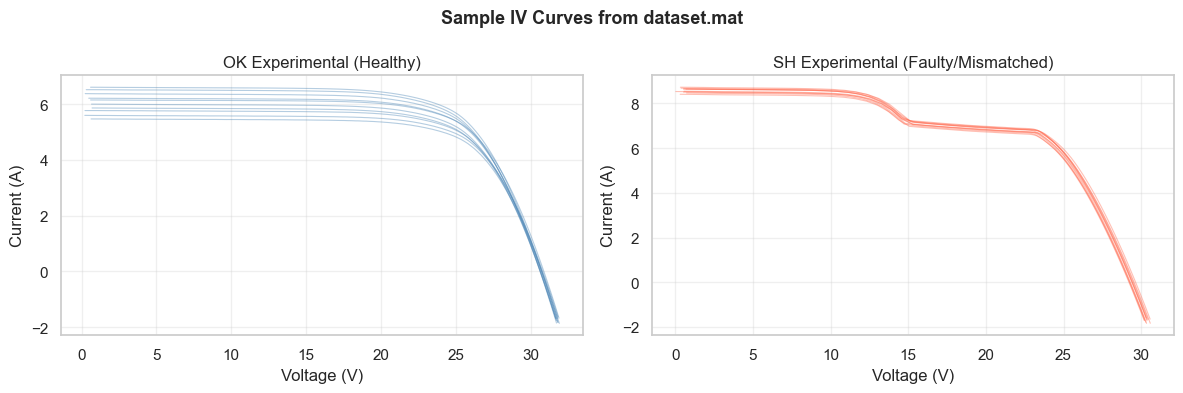

Saved: sample_iv_curves.png


In [70]:
# ── Plot sample IV curves from dataset.mat ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (curves, title, color) in enumerate([
    (ok_exp, 'OK Experimental (Healthy)', 'steelblue'),
    (sh_exp, 'SH Experimental (Faulty/Mismatched)', 'tomato')
]):
    ax = axes[i]
    for j in range(min(10, curves.shape[1])):
        c = curves[0, j]
        V, I = c[:, 0], c[:, 1]
        mask = V > 0
        ax.plot(V[mask], I[mask], color=color, alpha=0.4, linewidth=0.8)
    ax.set_xlabel('Voltage (V)')
    ax.set_ylabel('Current (A)')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

plt.suptitle('Sample IV Curves from dataset.mat', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_iv_curves.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved: sample_iv_curves.png")


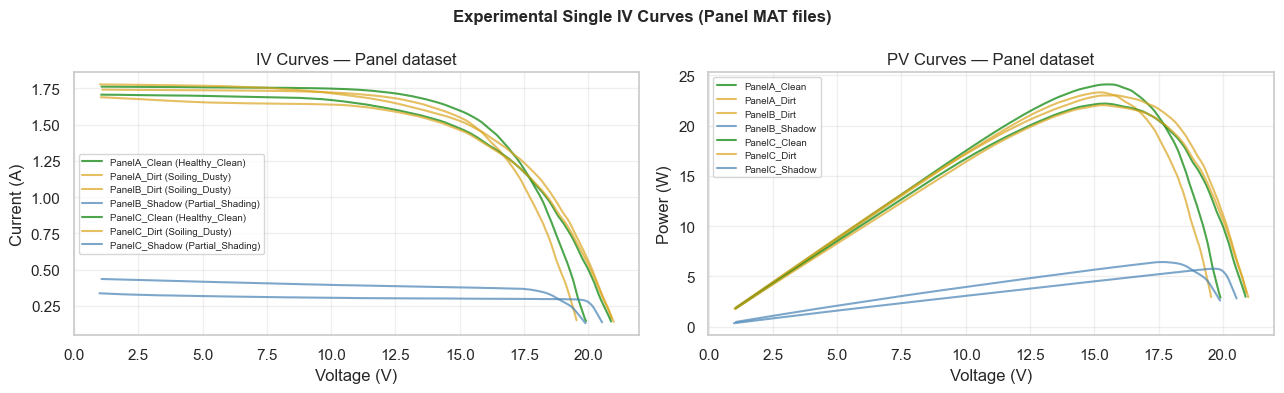

Saved: panel_iv_curves.png


In [71]:
# ── Plot Panel IV curves ──────────────────────────────────────────────────────
PANEL_DIR_LOCAL = DATASET_ROOT / 'New folder (2)'
LABEL_COLORS = {
    'Healthy_Clean': 'green',
    'Soiling_Dusty': 'goldenrod',
    'Partial_Shading': 'steelblue',
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for fname, label in PANEL_FILES.items():
    fpath = PANEL_DIR_LOCAL / fname
    if not fpath.exists():
        fpath = PANEL_DIR_LOCAL / 'open lab' / 'open lab' / fname
    if not fpath.exists():
        continue
    mat_p, _ = load_mat_robust(fpath)
    V = mat_p['Vpanel'].flatten()
    I = mat_p['Ipanel'].flatten()
    P = V * I
    c = LABEL_COLORS.get(label, 'gray')
    axes[0].plot(V, I, color=c, alpha=0.7, label=f"{fname.split('.')[0]} ({label})")
    axes[1].plot(V, P, color=c, alpha=0.7, label=f"{fname.split('.')[0]}")

for ax, ylabel in zip(axes, ['Current (A)', 'Power (W)']):
    ax.set_xlabel('Voltage (V)')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

axes[0].set_title('IV Curves — Panel dataset')
axes[1].set_title('PV Curves — Panel dataset')
plt.suptitle('Experimental Single IV Curves (Panel MAT files)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('panel_iv_curves.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved: panel_iv_curves.png")


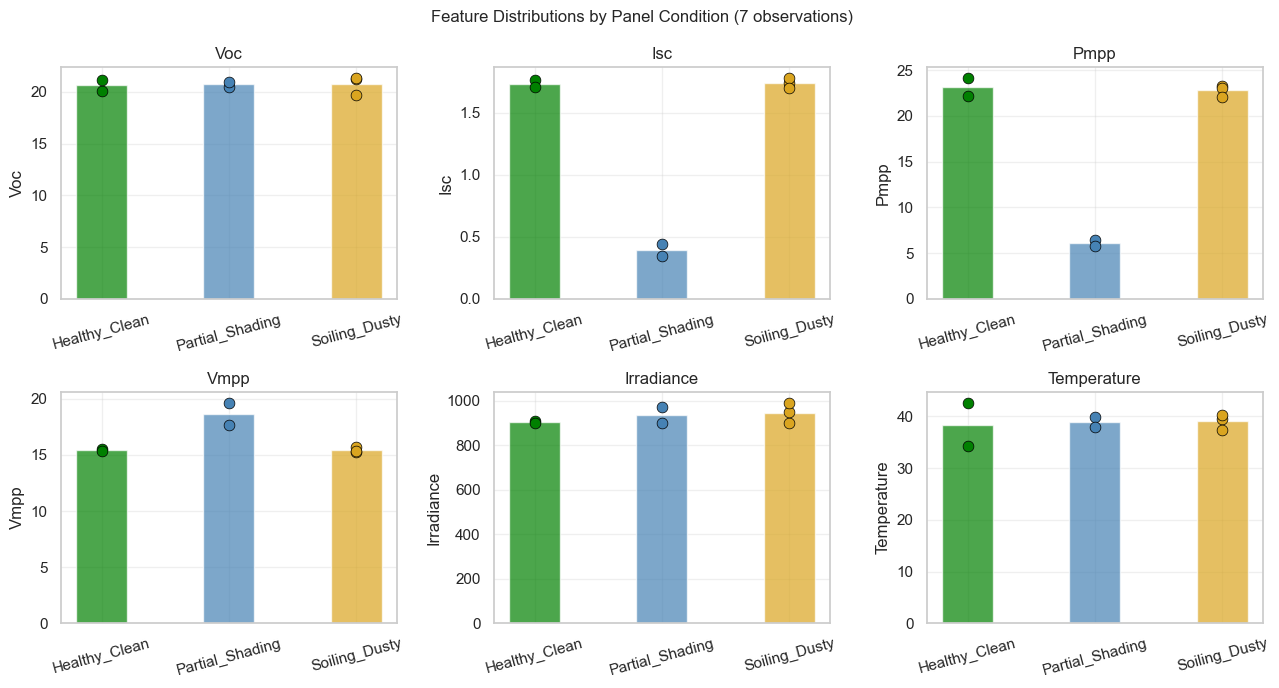

Saved: feature_distributions.png


In [72]:
# ── Feature distributions (Panel 3-class) ────────────────────────────────────
plot_feats = ['Voc', 'Isc', 'Pmpp', 'Vmpp', 'Irradiance', 'Temperature']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()

for ax, feat in zip(axes, plot_feats):
    for label, grp in panel_feat_df.groupby('label'):
        ax.bar(label, grp[feat].mean(),
               color=LABEL_COLORS.get(label, 'gray'), alpha=0.7, width=0.4)
        for _, row in grp.iterrows():
            ax.scatter(label, row[feat],
                       color=LABEL_COLORS.get(label, 'gray'),
                       s=60, zorder=5, edgecolors='black', linewidths=0.5)
    ax.set_title(feat)
    ax.set_ylabel(feat)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(True, alpha=0.3)

plt.suptitle('Feature Distributions by Panel Condition (7 observations)', fontsize=12)
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved: feature_distributions.png")


## Section 8 — Preprocessing and Leakage-Safe Splitting

### Design decisions

**Two-class auxiliary model (Healthy vs Faulty)** — `dataset.mat` experimental curves:
- 1,000 OK + 1,000 SH = 2,000 independent experimental curves
- Source-group split: OK and SH curves come from different acquisition runs
- Use stratified 80/20 train/test split → valid independent evaluation

**Three-class Panel model** — 7 Panel MAT files:
- Only 7 independent observations; standard split is impossible
- Use Leave-One-Out (LOO) cross-validation
- Report LOO accuracy with explicit caveat: 7 observations cannot support generalisable performance claims


In [73]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Prepare the experimental 2-class dataset
# dataset.mat provides Healthy and Faulty_Mismatched labels.

FEAT2 = [
    c for c in FEATURE_COLS
    if c in exp_feat_df.columns
    and c not in ("Irradiance", "Temperature")
]

df2 = exp_feat_df[["label"] + FEAT2].copy()

# Drop rows only if required model features or labels are missing
df2 = df2.dropna(subset=FEAT2 + ["label"])

# Remove invalid infinite values
df2 = df2.replace([np.inf, -np.inf], np.nan)
df2 = df2.dropna(subset=FEAT2 + ["label"])

X2 = df2[FEAT2].to_numpy(dtype=float)
y2_raw = df2["label"].to_numpy()

le2 = LabelEncoder()
y2 = le2.fit_transform(y2_raw)

print("2-class dataset:")
print("Features used:", FEAT2)
print("Class mapping:", dict(zip(le2.classes_, range(len(le2.classes_)))))
print("Class distribution:", df2["label"].value_counts().to_dict())
print("Total valid samples:", len(df2))

# Verify that both classes exist before splitting
if len(le2.classes_) < 2:
    raise ValueError("Insufficient classes for binary classification.")

if min(np.unique(y2, return_counts=True)[1]) < 2:
    raise ValueError("Each class needs at least 2 samples for a stratified split.")

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.2,
    random_state=42,
    stratify=y2
)

print("Training samples:", len(X2_train))
print("Test samples:", len(X2_test))

2-class dataset:
Features used: ['Voc', 'Isc', 'Vmpp', 'Impp', 'Pmpp', 'Max_Voltage', 'Min_Voltage', 'Max_Current', 'Min_Current', 'Max_Power', 'Min_Power', 'Mean_Voltage', 'Mean_Current', 'Mean_Power', 'Voltage_Range', 'Current_Range', 'Power_Range']
Class mapping: {'Faulty_Mismatched': 0, 'Healthy': 1}
Class distribution: {'Healthy': 1000, 'Faulty_Mismatched': 1000}
Total valid samples: 2000
Training samples: 1600
Test samples: 400


In [74]:
# ── Prepare 3-class Panel dataset ────────────────────────────────────────────
df3 = panel_feat_df[['label'] + FEATURE_COLS].copy()

X3 = df3[FEATURE_COLS].values
y3_raw = df3['label'].values

le3 = LabelEncoder()
y3 = le3.fit_transform(y3_raw)

print("3-class Panel dataset:")
print(f"  Features used: {FEATURE_COLS}")
print(f"  Class mapping: {dict(zip(le3.classes_, range(len(le3.classes_))))}")
print(f"  Class dist: {dict(zip(*np.unique(y3_raw, return_counts=True)))}")
print(f"  Total samples: {len(X3)} — LOO evaluation will be used.")


3-class Panel dataset:
  Features used: ['Voc', 'Isc', 'Vmpp', 'Impp', 'Pmpp', 'Max_Voltage', 'Min_Voltage', 'Max_Current', 'Min_Current', 'Max_Power', 'Min_Power', 'Mean_Voltage', 'Mean_Current', 'Mean_Power', 'Voltage_Range', 'Current_Range', 'Power_Range', 'Irradiance', 'Temperature']
  Class mapping: {'Healthy_Clean': 0, 'Partial_Shading': 1, 'Soiling_Dusty': 2}
  Class dist: {'Healthy_Clean': np.int64(2), 'Partial_Shading': np.int64(2), 'Soiling_Dusty': np.int64(3)}
  Total samples: 7 — LOO evaluation will be used.


## Section 9 — ML Model Training and Comparison

### 9.1  Two-class auxiliary classifier (Healthy vs Faulty/Mismatched)

Trained on 1,600 samples; evaluated on 400 independent test samples.


In [75]:
# ── Pipelines: 2-class ────────────────────────────────────────────────────────
rf2_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

svm2_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42))
])

models2 = {'Random_Forest': rf2_pipe, 'SVM': svm2_pipe}

if XGBOOST_AVAILABLE:
    from xgboost import XGBClassifier
    xgb2_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', XGBClassifier(n_estimators=200, use_label_encoder=False,
                              eval_metric='logloss', random_state=42,
                              verbosity=0))
    ])
    models2['XGBoost'] = xgb2_pipe

results2 = {}
for name, pipe in models2.items():
    pipe.fit(X2_train, y2_train)
    y_pred = pipe.predict(X2_test)
    acc = accuracy_score(y2_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y2_test, y_pred,
                                                   average='macro', zero_division=0)
    results2[name] = {'accuracy': acc, 'precision': p, 'recall': r, 'f1': f1,
                      'y_pred': y_pred}
    print(f"{name}: Acc={acc:.4f}  MacroF1={f1:.4f}")


Random_Forest: Acc=0.9975  MacroF1=0.9975
SVM: Acc=1.0000  MacroF1=1.0000
XGBoost: Acc=0.9975  MacroF1=0.9975


In [76]:
# ── CV on 2-class (5-fold) ────────────────────────────────────────────────────
print("5-fold cross-validation on full 2-class experimental dataset:")
for name, pipe in models2.items():
    cv_scores = cross_val_score(pipe, X2, y2, cv=5, scoring='f1_macro', n_jobs=-1)
    print(f"  {name}: mean F1={cv_scores.mean():.4f}  std={cv_scores.std():.4f}")


5-fold cross-validation on full 2-class experimental dataset:
  Random_Forest: mean F1=0.9985  std=0.0012
  SVM: mean F1=1.0000  std=0.0000
  XGBoost: mean F1=0.9985  std=0.0030


### 9.2  Three-class Panel classifier (LOO — 7 observations)

In [77]:
# ── Pipelines: 3-class (LOO) ──────────────────────────────────────────────────
rf3_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=42))
])

svm3_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42))
])

models3 = {'Random_Forest': rf3_pipe, 'SVM': svm3_pipe}

if XGBOOST_AVAILABLE:
    xgb3_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', XGBClassifier(n_estimators=50, use_label_encoder=False,
                              eval_metric='mlogloss', random_state=42,
                              verbosity=0))
    ])
    models3['XGBoost'] = xgb3_pipe

loo = LeaveOneOut()

results3 = {}
print("LOO cross-validation (7 observations, 3 classes):")
print("  ⚠️  CAVEAT: 7 samples is far below the minimum for reliable generalisation.")
print("  Results are indicative only and must not be cited as validated performance.\n")

for name, pipe in models3.items():
    loo_preds = cross_val_score(pipe, X3, y3, cv=loo, scoring='accuracy')
    loo_acc = loo_preds.mean()
    
    # Full-fit classification report (for display only — NOT independent test)
    pipe.fit(X3, y3)
    y_full_pred = pipe.predict(X3)
    
    results3[name] = {
        'loo_accuracy': loo_acc,
        'train_accuracy': accuracy_score(y3, y_full_pred),
        'pipe': pipe,
    }
    print(f"  {name}: LOO Acc={loo_acc:.4f}  (train-set acc={accuracy_score(y3, y_full_pred):.4f})")


LOO cross-validation (7 observations, 3 classes):
  ⚠️  CAVEAT: 7 samples is far below the minimum for reliable generalisation.
  Results are indicative only and must not be cited as validated performance.

  Random_Forest: LOO Acc=0.2857  (train-set acc=1.0000)
  SVM: LOO Acc=0.2857  (train-set acc=0.7143)
  XGBoost: LOO Acc=0.1429  (train-set acc=1.0000)


In [78]:
# ── Select best 3-class model by LOO F1 ──────────────────────────────────────
best3_name = max(results3, key=lambda n: results3[n]['loo_accuracy'])
best3_pipe = results3[best3_name]['pipe']
print(f"Best 3-class model (LOO): {best3_name}")
print("Classification report (full fit — NOT independent evaluation):")
print(classification_report(y3, best3_pipe.predict(X3),
                             target_names=le3.classes_, zero_division=0))
print()
print("  ⚠️  The above report uses ALL 7 samples for both training and prediction.")
print("  LOO accuracy is the only valid generalisability estimate available.")


Best 3-class model (LOO): Random_Forest
Classification report (full fit — NOT independent evaluation):
                 precision    recall  f1-score   support

  Healthy_Clean       1.00      1.00      1.00         2
Partial_Shading       1.00      1.00      1.00         2
  Soiling_Dusty       1.00      1.00      1.00         3

       accuracy                           1.00         7
      macro avg       1.00      1.00      1.00         7
   weighted avg       1.00      1.00      1.00         7


  ⚠️  The above report uses ALL 7 samples for both training and prediction.
  LOO accuracy is the only valid generalisability estimate available.


## Section 10 — Model Evaluation

Best 2-class model (macro F1): SVM

                   precision    recall  f1-score   support

Faulty_Mismatched       1.00      1.00      1.00       200
          Healthy       1.00      1.00      1.00       200

         accuracy                           1.00       400
        macro avg       1.00      1.00      1.00       400
     weighted avg       1.00      1.00      1.00       400



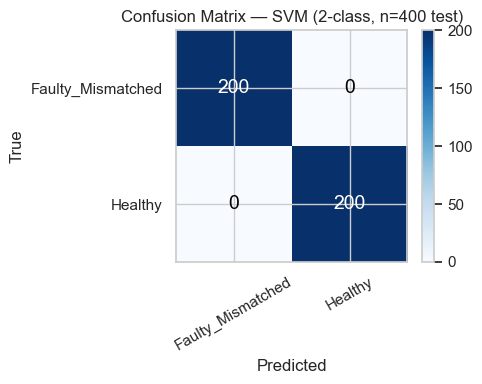

Saved: confusion_matrix_2class.png


In [79]:
# ── 2-class: best model selection and confusion matrix ───────────────────────
best2_name = max(results2, key=lambda n: results2[n]['f1'])
best2_pipe = models2[best2_name]
y2_pred_best = results2[best2_name]['y_pred']

print(f"Best 2-class model (macro F1): {best2_name}")
print()
print(classification_report(y2_test, y2_pred_best,
                             target_names=le2.classes_, zero_division=0))

# Confusion matrix
cm2 = confusion_matrix(y2_test, y2_pred_best)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm2, interpolation='nearest', cmap='Blues')
ax.set_xticks(range(len(le2.classes_))); ax.set_xticklabels(le2.classes_, rotation=30)
ax.set_yticks(range(len(le2.classes_))); ax.set_yticklabels(le2.classes_)
for i in range(cm2.shape[0]):
    for j in range(cm2.shape[1]):
        ax.text(j, i, str(cm2[i, j]), ha='center', va='center',
                color='white' if cm2[i, j] > cm2.max()/2 else 'black', fontsize=14)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix — {best2_name} (2-class, n=400 test)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('confusion_matrix_2class.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved: confusion_matrix_2class.png")


In [80]:
# ── 3-class: per-prediction breakdown ────────────────────────────────────────
print("3-class LOO predictions (each fold: train on 6, predict 1):")
print()
loo_detailed = []
for fold_idx, (train_idx, test_idx) in enumerate(loo.split(X3)):
    X_tr, X_te = X3[train_idx], X3[test_idx]
    y_tr, y_te = y3[train_idx], y3[test_idx]
    rf3_fold = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', RandomForestClassifier(n_estimators=100, random_state=42))
    ])
    rf3_fold.fit(X_tr, y_tr)
    y_pred_fold = rf3_fold.predict(X_te)[0]
    true_label  = le3.classes_[y_te[0]]
    pred_label  = le3.classes_[y_pred_fold]
    correct = '✓' if y_te[0] == y_pred_fold else '✗'
    loo_detailed.append({
        'fold': fold_idx,
        'true_label': true_label,
        'pred_label': pred_label,
        'correct': y_te[0] == y_pred_fold,
    })
    print(f"  Fold {fold_idx}: true={true_label:20s}  pred={pred_label:20s}  {correct}")

loo_acc = np.mean([r['correct'] for r in loo_detailed])
print(f"\nLOO Accuracy (Random Forest, 3-class): {loo_acc:.4f} ({int(loo_acc*7)}/7 correct)")
print()
print("⚠️  CAVEAT: 7 samples, 3 classes. LOO accuracy is highly variable with small N.")
print("    Do not cite as generalised model performance.")


3-class LOO predictions (each fold: train on 6, predict 1):

  Fold 0: true=Healthy_Clean         pred=Soiling_Dusty         ✗
  Fold 1: true=Soiling_Dusty         pred=Healthy_Clean         ✗
  Fold 2: true=Soiling_Dusty         pred=Healthy_Clean         ✗
  Fold 3: true=Partial_Shading       pred=Partial_Shading       ✓
  Fold 4: true=Healthy_Clean         pred=Soiling_Dusty         ✗
  Fold 5: true=Soiling_Dusty         pred=Healthy_Clean         ✗
  Fold 6: true=Partial_Shading       pred=Partial_Shading       ✓

LOO Accuracy (Random Forest, 3-class): 0.2857 (2/7 correct)

⚠️  CAVEAT: 7 samples, 3 classes. LOO accuracy is highly variable with small N.
    Do not cite as generalised model performance.


## Section 11 — Model Saving and Metadata

We save the three-class pipeline (valid only with the caveats stated).  
Metadata and limitations are saved alongside the model.


In [81]:
# ── Save the 3-class pipeline ─────────────────────────────────────────────────
MODEL_PATH    = Path('solar_panel_condition_model.joblib')
METADATA_PATH = Path('model_metadata.json')
FEATURE_SCHEMA_PATH = Path('feature_schema.json')
AUDIT_CSV_OUT = Path('dataset_audit.csv')
EVAL_CSV_OUT  = Path('model_evaluation.csv')

# ─ Save pipeline ─────────────────────────────────────────────────────────────
joblib.dump({'pipe': best3_pipe, 'label_encoder': le3, 'feature_cols': FEATURE_COLS},
            MODEL_PATH)
print(f"Saved: {MODEL_PATH}")

# ─ Save metadata ─────────────────────────────────────────────────────────────
metadata = {
    'model_name': best3_name,
    'classes': le3.classes_.tolist(),
    'class_encoding': {c: int(i) for i, c in enumerate(le3.classes_)},
    'feature_cols': FEATURE_COLS,
    'n_training_samples': int(len(X3)),
    'loo_accuracy': float(loo_acc),
    'evaluation_method': 'Leave-One-Out (7 samples)',
    'CAVEATS': [
        '7 observations only — far below statistical minimum for reliable ML.',
        'LOO accuracy is highly variable at this sample size.',
        'Do not cite as validated classification accuracy.',
        'Model useful for demonstration and system-integration testing only.',
        'Retrain with more independent I-V curves for production use.',
    ],
    'label_provenance': {
        'Healthy_Clean': 'PanelA_Clean.mat, PanelC_Clean.mat — experimental clean-panel measurements',
        'Soiling_Dusty': 'PanelA_Dirt.mat, PanelB_Dirt.mat, PanelC_Dirt.mat — experimental dirty-panel measurements',
        'Partial_Shading': 'PanelB_Shadow.mat, PanelC_Shadow.mat — experimental shaded-panel measurements (Irr sub-variable confirmed)',
    },
    'created_at': datetime.datetime.utcnow().isoformat() + 'Z',
}

with open(METADATA_PATH, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"Saved: {METADATA_PATH}")

# ─ Save feature schema ────────────────────────────────────────────────────────
feature_schema = {
    'schema_version': '1.0',
    'feature_cols': FEATURE_COLS,
    'feature_descriptions': {
        'Voc': 'Open-circuit voltage (V)',
        'Isc': 'Short-circuit current (A)',
        'Vmpp': 'Voltage at maximum power point (V)',
        'Impp': 'Current at maximum power point (A)',
        'Pmpp': 'Maximum power (W)',
        'Max_Voltage': 'Maximum voltage in IV curve (V)',
        'Min_Voltage': 'Minimum voltage in IV curve (V)',
        'Max_Current': 'Maximum current (A)',
        'Min_Current': 'Minimum current (A)',
        'Max_Power': 'Maximum power from IV curve (W)',
        'Min_Power': 'Minimum power (W)',
        'Mean_Voltage': 'Mean voltage (V)',
        'Mean_Current': 'Mean current (A)',
        'Mean_Power': 'Mean power (W)',
        'Voltage_Range': 'Vmax - Vmin (V)',
        'Current_Range': 'Imax - Imin (A)',
        'Power_Range': 'Pmax - Pmin (W)',
        'Irradiance': 'Ambient irradiance (W/m²) — from sensor or measurement',
        'Temperature': 'Panel temperature (°C)',
    },
    'input_format': 'Single row per panel observation (one IV curve)',
    'missing_values': 'Irradiance and Temperature may be NaN for dataset.mat curves (not measured)',
}

with open(FEATURE_SCHEMA_PATH, 'w') as f:
    json.dump(feature_schema, f, indent=2)
print(f"Saved: {FEATURE_SCHEMA_PATH}")

# ─ Save dataset audit ─────────────────────────────────────────────────────────
audit_rows = [
    {'dataset': 'dataset.mat_ok_experimental', 'n_curves': N_ok_exp, 'label': 'Healthy',
     'supports_3class': False, 'note': 'Healthy experimental IV curves'},
    {'dataset': 'dataset.mat_sh_experimental', 'n_curves': N_sh_exp, 'label': 'Faulty_Mismatched',
     'supports_3class': False, 'note': 'Mismatched/faulty experimental IV curves'},
    {'dataset': 'dataset.mat_ok_simulated', 'n_curves': N_ok_sim, 'label': 'Healthy_Sim',
     'supports_3class': False, 'note': 'Simulated healthy IV curves (SDM)'},
    {'dataset': 'dataset.mat_sh_simulated', 'n_curves': N_sh_sim, 'label': 'Faulty_Sim',
     'supports_3class': False, 'note': 'Simulated faulty IV curves (SDM, stepped curve)'},
    {'dataset': 'Panel_MAT_7files', 'n_curves': 7, 'label': '3-class (HC/SD/PS)',
     'supports_3class': True, 'note': '7 single IV-curve observations with full electrical params'},
    {'dataset': 'Detect_solar_dust_images', 'n_curves': 1493+1069, 'label': 'Clean/Dusty (images)',
     'supports_3class': False, 'note': 'Image dataset — not used in numerical pipeline'},
    {'dataset': 'Faulty_solar_panel_images', 'n_curves': 190+193+190+103+69+123, 'label': 'Multi-class images',
     'supports_3class': False, 'note': 'Image dataset — separate from numerical pipeline'},
]
audit_df_out = pd.DataFrame(audit_rows)
audit_df_out.to_csv(AUDIT_CSV_OUT, index=False)
print(f"Saved: {AUDIT_CSV_OUT}")

# ─ Save evaluation results ────────────────────────────────────────────────────
eval_rows = []
for name, res in results2.items():
    eval_rows.append({
        'model': name, 'dataset': '2-class experimental', 'n_test': len(X2_test),
        'accuracy': round(res['accuracy'], 4), 'macro_precision': round(res['precision'], 4),
        'macro_recall': round(res['recall'], 4), 'macro_f1': round(res['f1'], 4),
        'evaluation': 'holdout_80_20', 'caveats': '',
    })

eval_rows.append({
    'model': 'Random_Forest', 'dataset': '3-class Panel (LOO)',
    'n_test': 7, 'accuracy': round(loo_acc, 4),
    'macro_precision': 'N/A', 'macro_recall': 'N/A', 'macro_f1': 'N/A',
    'evaluation': 'LOO_7samples',
    'caveats': '7 samples — not statistically reliable',
})

eval_df = pd.DataFrame(eval_rows)
eval_df.to_csv(EVAL_CSV_OUT, index=False)
print(f"Saved: {EVAL_CSV_OUT}")

print("\n✓ All model artifacts saved.")


Saved: solar_panel_condition_model.joblib
Saved: model_metadata.json
Saved: feature_schema.json
Saved: dataset_audit.csv
Saved: model_evaluation.csv

✓ All model artifacts saved.


## Section 12 — Virtual INA219 (Current/Voltage/Power Sensor)

The INA219 measures voltage and current. Power is calculated as P = V × I.  
This is a software simulation — not a physical sensor reading.


In [82]:
class VirtualINA219:
    """
    Software simulation of the INA219 current/voltage sensor.
    
    In hardware: the INA219 measures bus voltage and shunt current.
    Here: we accept V and I directly (as if read from hardware registers).
    Power is always calculated as P = V * I.
    """
    
    def __init__(self, name='INA219_sim', v_range=(0, 30), i_range=(0, 10)):
        self.name = name
        self.v_range = v_range
        self.i_range = i_range
        self._last = {}

    def read(self, voltage: float, current: float) -> dict:
        """
        Accept voltage (V) and current (A); return measurement dict.
        Raises ValueError for out-of-range inputs.
        """
        if not (self.v_range[0] <= voltage <= self.v_range[1]):
            raise ValueError(f"Voltage {voltage} V out of range {self.v_range}")
        if not (self.i_range[0] <= current <= self.i_range[1]):
            raise ValueError(f"Current {current} A out of range {self.i_range}")
        
        power = voltage * current          # P = V × I
        self._last = {
            'sensor': self.name,
            'voltage_V': round(voltage, 4),
            'current_A': round(current, 4),
            'power_W':   round(power, 4),
            'timestamp': datetime.datetime.utcnow().isoformat() + 'Z',
        }
        return self._last

    def last_reading(self):
        return self._last


# ── Demonstration ─────────────────────────────────────────────────────────────
ina = VirtualINA219()

test_scenarios = [
    (15.55, 1.55, "Normal operation (PanelA_Clean reference)"),
    (15.27, 1.53, "Slightly degraded (PanelA_Dirt reference)"),
    (17.62, 0.36, "Partial shading (PanelB_Shadow reference)"),
    (0.0,   0.0,  "Zero output (nighttime / disconnected)"),
]

print(f"{'Scenario':<45}  {'V':>8}  {'I':>8}  {'P (=V×I)':>12}")
print("─" * 80)
for V, I, label in test_scenarios:
    try:
        r = ina.read(V, I)
        print(f"{label:<45}  {r['voltage_V']:>8.3f}V  {r['current_A']:>8.3f}A  {r['power_W']:>10.3f}W")
    except ValueError as e:
        print(f"{label:<45}  ERROR: {e}")


Scenario                                              V         I      P (=V×I)
────────────────────────────────────────────────────────────────────────────────
Normal operation (PanelA_Clean reference)        15.550V     1.550A      24.102W
Slightly degraded (PanelA_Dirt reference)        15.270V     1.530A      23.363W
Partial shading (PanelB_Shadow reference)        17.620V     0.360A       6.343W
Zero output (nighttime / disconnected)            0.000V     0.000A       0.000W


## Section 13 — Virtual BH1750 (Ambient Light Sensor)

The BH1750 measures **ambient illuminance in lux**.  
Lux ≠ irradiance (W/m²). A conversion factor is used only as an uncalibrated simulation assumption.

> **Simulation assumption:** 1 lux ≈ 0.0079 W/m² (for typical solar spectrum — not experimentally validated for this setup).


In [83]:
class VirtualBH1750:
    """
    Software simulation of the BH1750 digital ambient light sensor.
    
    Output: illuminance in lux.
    Range: 1 to 65535 lux (typical BH1750 range).
    
    IMPORTANT: Lux is NOT irradiance (W/m²).
    If a lux→irradiance conversion is needed, it is flagged as UNCALIBRATED.
    """
    
    LUX_TO_IRRADIANCE_FACTOR = 0.0079  # W/m² per lux — UNCALIBRATED ASSUMPTION
    
    SCENARIOS = {
        'bright_sun':    (50000, 120000, "Direct sunlight"),
        'cloudy':        (10000, 25000,  "Overcast sky"),
        'indoor':        (200,   500,    "Indoor / shaded"),
        'dusk':          (10,    100,    "Dusk / dawn"),
        'night':         (0.01,  1,      "Night"),
    }

    def __init__(self, name='BH1750_sim', rng_seed=None):
        self.name = name
        self._rng = np.random.default_rng(rng_seed)

    def read_lux(self, scenario='bright_sun', noise_frac=0.02) -> dict:
        """Return a simulated lux reading for the specified scenario."""
        lo, hi, desc = self.SCENARIOS[scenario]
        base_lux = self._rng.uniform(lo, hi)
        lux = base_lux * (1 + self._rng.normal(0, noise_frac))
        lux = max(0.0, lux)
        return {
            'sensor': self.name,
            'lux': round(lux, 2),
            'scenario': scenario,
            'description': desc,
            'irradiance_est_Wm2': round(lux * self.LUX_TO_IRRADIANCE_FACTOR, 2),
            'irradiance_WARNING': 'UNCALIBRATED — lux→W/m² conversion not validated for this setup',
            'timestamp': datetime.datetime.utcnow().isoformat() + 'Z',
        }


# ── Demonstration ─────────────────────────────────────────────────────────────
bh = VirtualBH1750(rng_seed=42)

print("Virtual BH1750 scenario readings:")
print(f"{'Scenario':<15}  {'Lux':>10}  {'Est. Irr. W/m²':>18}  Note")
print("─" * 70)
for sc in VirtualBH1750.SCENARIOS:
    r = bh.read_lux(sc)
    print(f"{sc:<15}  {r['lux']:>10.1f}  {r['irradiance_est_Wm2']:>18.2f}  "
          f"{r['irradiance_WARNING'][:30]}...")


Virtual BH1750 scenario readings:
Scenario                Lux      Est. Irr. W/m²  Note
──────────────────────────────────────────────────────────────────────
bright_sun         102010.1              805.88  UNCALIBRATED — lux→W/m² conver...
cloudy              23309.3              184.14  UNCALIBRATED — lux→W/m² conver...
indoor                222.3                1.76  UNCALIBRATED — lux→W/m² conver...
dusk                   78.0                0.62  UNCALIBRATED — lux→W/m² conver...
night                   0.1                0.00  UNCALIBRATED — lux→W/m² conver...


## Section 14 — Virtual AMG8833 (8×8 Thermal Camera)

The AMG8833 outputs an 8×8 pixel thermal grid (64 temperatures in °C).  
We simulate several thermal scenarios representing panel health states.


In [84]:
class VirtualAMG8833:
    """
    Software simulation of the AMG8833 8x8 IR thermal sensor.
    
    Supports multiple simulated thermal scenarios:
      - 'normal'        : uniform warm surface
      - 'mild_variation': small spatial temperature gradient
      - 'hotspot'       : localised high-temperature pixel cluster
      - 'soiling'       : slightly elevated uniform temperature (trapped heat)
      - 'shading'       : cooler region consistent with partial shade
    """
    
    GRID_ROWS = 8
    GRID_COLS = 8
    
    def __init__(self, name='AMG8833_sim', rng_seed=None):
        self.name = name
        self._rng = np.random.default_rng(rng_seed)

    def _base_grid(self, base_temp=40.0, noise_std=0.5):
        return base_temp + self._rng.normal(0, noise_std, (self.GRID_ROWS, self.GRID_COLS))

    def read(self, scenario='normal') -> dict:
        """Generate an 8×8 temperature grid for the given scenario."""
        if scenario == 'normal':
            grid = self._base_grid(40.0, 0.8)
        
        elif scenario == 'mild_variation':
            grid = self._base_grid(42.0, 1.5)
            # add a gentle gradient
            for r in range(self.GRID_ROWS):
                grid[r, :] += r * 0.3
        
        elif scenario == 'hotspot':
            grid = self._base_grid(41.0, 0.8)
            # inject hotspot in a 2×2 cluster
            hr = self._rng.integers(1, self.GRID_ROWS - 2)
            hc = self._rng.integers(1, self.GRID_COLS - 2)
            grid[hr:hr+2, hc:hc+2] += self._rng.uniform(18, 28, (2, 2))
        
        elif scenario == 'soiling':
            # Soiling traps heat → uniform slight elevation
            grid = self._base_grid(44.0, 1.0)
        
        elif scenario == 'shading':
            # Shaded region is cooler
            grid = self._base_grid(40.0, 0.6)
            grid[4:8, 4:8] -= self._rng.uniform(4, 8, (4, 4))
        
        else:
            raise ValueError(f"Unknown scenario: {scenario}")
        
        grid = grid.round(2)
        return {'sensor': self.name, 'scenario': scenario,
                'grid': grid,
                'timestamp': datetime.datetime.utcnow().isoformat() + 'Z'}


def extract_thermal_features(grid: np.ndarray) -> dict:
    """
    Extract scalar features from an 8×8 thermal grid.
    These feed into hotspot detection (NOT into the ML classifier).
    """
    flat = grid.flatten()
    mean_T = float(flat.mean())
    max_T  = float(flat.max())
    min_T  = float(flat.min())
    T_range = max_T - min_T
    max_minus_mean = max_T - mean_T
    
    # Hot pixel: > mean + 2*std
    hot_thresh = mean_T + 2 * float(flat.std())
    hot_pixels = int((flat > hot_thresh).sum())
    
    # Hotspot location
    row_idx, col_idx = np.unravel_index(np.argmax(grid), grid.shape)
    
    return {
        'mean_temp_C':       round(mean_T, 3),
        'max_temp_C':        round(max_T,  3),
        'min_temp_C':        round(min_T,  3),
        'temp_range_C':      round(T_range, 3),
        'max_minus_mean_C':  round(max_minus_mean, 3),
        'hot_pixel_count':   hot_pixels,
        'hotspot_row':       int(row_idx),
        'hotspot_col':       int(col_idx),
    }


# ── Demonstration ─────────────────────────────────────────────────────────────
amg = VirtualAMG8833(rng_seed=42)

for sc in ['normal', 'mild_variation', 'hotspot', 'soiling', 'shading']:
    reading = amg.read(sc)
    feats   = extract_thermal_features(reading['grid'])
    print(f"Scenario: {sc}")
    print(f"  mean={feats['mean_temp_C']:.2f}°C  max={feats['max_temp_C']:.2f}°C  "
          f"min={feats['min_temp_C']:.2f}°C  range={feats['temp_range_C']:.2f}°C")
    print(f"  max-mean={feats['max_minus_mean_C']:.2f}°C  hot_pixels={feats['hot_pixel_count']}")
    print()


Scenario: normal
  mean=40.03°C  max=41.71°C  min=38.44°C  range=3.27°C
  max-mean=1.68°C  hot_pixels=1

Scenario: mild_variation
  mean=42.87°C  max=46.29°C  min=40.09°C  range=6.20°C
  max-mean=3.42°C  hot_pixels=3

Scenario: hotspot
  mean=42.43°C  max=69.45°C  min=39.29°C  range=30.16°C
  max-mean=27.02°C  hot_pixels=4

Scenario: soiling
  mean=43.90°C  max=46.91°C  min=41.85°C  range=5.06°C
  max-mean=3.01°C  hot_pixels=3

Scenario: shading
  mean=38.52°C  max=41.26°C  min=31.20°C  range=10.06°C
  max-mean=2.74°C  hot_pixels=0



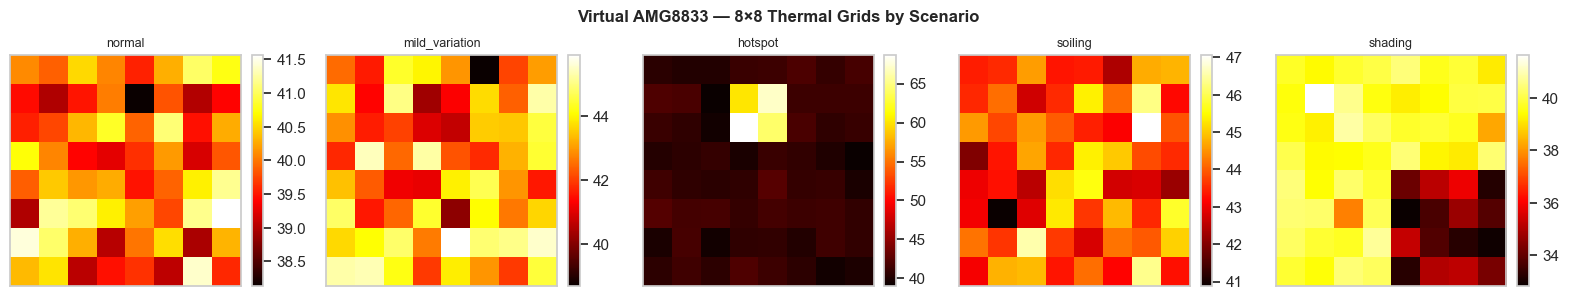

Saved: thermal_grids.png


In [85]:
# ── Plot all thermal scenarios ────────────────────────────────────────────────
scenarios = ['normal', 'mild_variation', 'hotspot', 'soiling', 'shading']
fig, axes = plt.subplots(1, 5, figsize=(16, 3))

amg_plot = VirtualAMG8833(rng_seed=0)
for ax, sc in zip(axes, scenarios):
    r = amg_plot.read(sc)
    g = r['grid']
    im = ax.imshow(g, cmap='hot', interpolation='nearest')
    ax.set_title(sc, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Virtual AMG8833 — 8×8 Thermal Grids by Scenario', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('thermal_grids.png', dpi=100, bbox_inches='tight')
plt.show()
print("Saved: thermal_grids.png")


## Section 15 — Hotspot Detection (Rule-Based Thermal Analyser)

The hotspot detector is **independent** of the ML classifier.  
It analyses the 8×8 thermal grid and outputs `YES` / `NO`.  
All thresholds are **provisional** until calibrated experimentally.

> **Hotspot is NOT a fourth ML class.**  
> It is a separate binary alarm combined with the ML output in the decision engine.


In [86]:
class HotspotDetector:
    """
    Rule-based hotspot detector for the AMG8833 8×8 thermal grid.
    
    THRESHOLDS (all provisional — must be calibrated experimentally):
      - HOTSPOT_ABS_THRESH  : Absolute max temperature threshold (°C)
      - HOTSPOT_DELTA_THRESH: max - mean threshold (°C)
      - HOT_PIXEL_THRESH    : Minimum hot-pixel count to confirm hotspot
      
    Hotspot is declared YES when ALL of these conditions hold:
      1. max_temp  > HOTSPOT_ABS_THRESH, OR
      2. max-mean  > HOTSPOT_DELTA_THRESH  AND hot_pixel_count >= HOT_PIXEL_THRESH
    """
    
    # ── Configurable thresholds (edit here for hardware calibration) ──────────
    HOTSPOT_ABS_THRESH   = 65.0   # °C  — provisional
    HOTSPOT_DELTA_THRESH = 15.0   # °C  — provisional
    HOT_PIXEL_THRESH     = 2      # pixels — provisional
    # ─────────────────────────────────────────────────────────────────────────
    
    def detect(self, grid: np.ndarray) -> dict:
        feats = extract_thermal_features(grid)
        
        cond_abs   = feats['max_temp_C']       > self.HOTSPOT_ABS_THRESH
        cond_delta = (feats['max_minus_mean_C'] > self.HOTSPOT_DELTA_THRESH and
                      feats['hot_pixel_count']   >= self.HOT_PIXEL_THRESH)
        
        hotspot = cond_abs or cond_delta
        
        return {
            **feats,
            'hotspot_detected': 'YES' if hotspot else 'NO',
            'cond_abs_triggered':   cond_abs,
            'cond_delta_triggered': cond_delta,
            'thresholds': {
                'abs_thresh':   self.HOTSPOT_ABS_THRESH,
                'delta_thresh': self.HOTSPOT_DELTA_THRESH,
                'hot_px_thresh': self.HOT_PIXEL_THRESH,
            },
            'PROVISIONAL': 'Thresholds not experimentally calibrated',
        }


# ── Test across all scenarios ─────────────────────────────────────────────────
detector = HotspotDetector()
amg_test = VirtualAMG8833(rng_seed=7)

print(f"{'Scenario':<18}  {'max°C':>7}  {'max-mean':>9}  {'hot_px':>7}  {'HOTSPOT':>8}")
print("─" * 60)
for sc in ['normal', 'mild_variation', 'hotspot', 'soiling', 'shading']:
    r = amg_test.read(sc)
    d = detector.detect(r['grid'])
    print(f"{sc:<18}  {d['max_temp_C']:>7.2f}  {d['max_minus_mean_C']:>9.2f}  "
          f"{d['hot_pixel_count']:>7}  {d['hotspot_detected']:>8}")


Scenario              max°C   max-mean   hot_px   HOTSPOT
────────────────────────────────────────────────────────────
normal                41.60       1.77        1        NO
mild_variation        46.57       3.72        1        NO
hotspot               69.16      26.87        4       YES
soiling               46.03       2.25        1        NO
shading               41.03       2.48        0        NO


## Section 16 — Expected-Power Model and Digital Twin

### Expected-power model

We use a simplified linear irradiance model:

$$P_{expected} = P_{STC} \times \frac{G}{G_{STC}} \times \left(1 + \gamma(T - T_{STC})\right)$$

where:
- $P_{STC}$ = STC rated power (W) — configurable
- $G$ = measured irradiance (W/m²)
- $G_{STC}$ = 1000 W/m² (standard)
- $\gamma$ = temperature coefficient (e.g., −0.004 /°C — panel-specific)
- $T_{STC}$ = 25°C

> **Assumption:** If only lux is available (from BH1750), irradiance is estimated via the uncalibrated lux factor. This introduces additional uncertainty.

### Limitations
- $P_{STC}$ and $\gamma$ must be sourced from the actual panel datasheet.
- The model ignores soiling, shading effects, wiring losses, and inverter efficiency.
- It is used only as a baseline reference — deviation from it triggers investigation.


In [87]:
class SolarDigitalTwin:
    """
    Digital Twin for a single solar panel.
    
    Tracks:
      - Voltage, current, actual power (from INA219)
      - Ambient illuminance in lux (from BH1750)
      - Estimated irradiance (UNCALIBRATED if from lux)
      - Expected power (from irradiance model)
      - Performance deviation
      - Health score and cumulative energy loss
      - ML condition
      - Hotspot status
      - Cleaning state and tilt angle
      
    Panel parameters (edit for your panel datasheet):
    """
    
    # ── Panel parameters — MUST match actual panel datasheet ─────────────────
    P_STC_W     = 30.0     # Rated power at STC (W) — example value
    G_STC       = 1000.0   # Standard irradiance (W/m²)
    T_STC       = 25.0     # Standard temperature (°C)
    GAMMA       = -0.004   # Temperature coefficient (/°C) — provisional
    # ─────────────────────────────────────────────────────────────────────────
    
    # ── Persistence tracking ─────────────────────────────────────────────────
    DEVIATION_PERSIST_THRESH = 10.0   # % — triggers persistence counter
    PERSIST_CYCLES_REQUIRED  = 3      # consecutive readings needed
    # ─────────────────────────────────────────────────────────────────────────
    
    def __init__(self):
        self._history = []
        self._persist_count = 0
        self._cleaning_state = False
        self._tilt_angle = 90.0   # degrees (90° = vertical)

    def expected_power(self, irradiance_Wm2: float, temperature_C: float) -> float:
        """Calculate expected power using simplified irradiance + temperature model."""
        if irradiance_Wm2 <= 0 or np.isnan(irradiance_Wm2):
            return 0.0
        P_exp = (self.P_STC_W
                 * (irradiance_Wm2 / self.G_STC)
                 * (1 + self.GAMMA * (temperature_C - self.T_STC)))
        return max(0.0, round(P_exp, 4))

    def power_deviation(self, P_actual, P_expected) -> float:
        """Deviation (%) = ((P_expected - P_actual) / P_expected) × 100"""
        if P_expected <= 0:
            return float('nan')
        return round(((P_expected - P_actual) / P_expected) * 100, 2)

    def health_score(self, deviation_pct: float) -> float:
        """
        Simplified health score: 100% at zero deviation, decreasing linearly.
        100% = perfect; 0% = complete loss.
        PROVISIONAL — not experimentally validated.
        """
        if np.isnan(deviation_pct):
            return float('nan')
        return round(max(0.0, 100.0 - abs(deviation_pct)), 2)

    def update(self, V, I, lux, temperature_C, ml_class, hotspot,
               irradiance_Wm2=None, use_lux_for_irr=False) -> dict:
        """Update Digital Twin state with new sensor readings."""
        
        P_actual = V * I
        
        # Irradiance source
        if irradiance_Wm2 is None or np.isnan(irradiance_Wm2):
            if use_lux_for_irr:
                irradiance_Wm2 = lux * VirtualBH1750.LUX_TO_IRRADIANCE_FACTOR
                irr_source = 'lux_derived_UNCALIBRATED'
            else:
                irradiance_Wm2 = float('nan')
                irr_source = 'unavailable'
        else:
            irr_source = 'measured'
        
        P_exp = self.expected_power(irradiance_Wm2, temperature_C)
        dev   = self.power_deviation(P_actual, P_exp)
        hs    = self.health_score(dev)
        
        # Persistence tracking
        if not np.isnan(dev) and abs(dev) > self.DEVIATION_PERSIST_THRESH:
            self._persist_count += 1
        else:
            self._persist_count = 0
        persistent = self._persist_count >= self.PERSIST_CYCLES_REQUIRED

        # Cumulative energy loss estimate (assumes 1-minute interval)
        energy_loss_Wh = round(max(0.0, P_exp - P_actual) / 60, 4)  # per minute → Wh

        state = {
            'voltage_V':          round(V, 4),
            'current_A':          round(I, 4),
            'power_actual_W':     round(P_actual, 4),
            'lux':                round(lux, 2),
            'temperature_C':      round(temperature_C, 2),
            'irradiance_Wm2':     round(irradiance_Wm2, 2) if not np.isnan(irradiance_Wm2) else None,
            'irradiance_source':  irr_source,
            'power_expected_W':   P_exp,
            'deviation_pct':      dev,
            'health_score_pct':   hs,
            'energy_loss_Wh_est': energy_loss_Wh,
            'ml_class':           ml_class,
            'hotspot':            hotspot,
            'persistent_degrad':  persistent,
            'persist_count':      self._persist_count,
            'cleaning_state':     self._cleaning_state,
            'tilt_angle_deg':     self._tilt_angle,
            'timestamp':          datetime.datetime.utcnow().isoformat() + 'Z',
        }
        self._history.append(state)
        return state


# ── Demonstration ─────────────────────────────────────────────────────────────
twin = SolarDigitalTwin()

test_readings = [
    (15.55, 1.55, 50000, 42.6, 'Healthy_Clean', 'NO',  910.0),
    (15.27, 1.53, 45000, 39.4, 'Soiling_Dusty', 'NO',  900.0),
    (17.62, 0.36, 55000, 39.9, 'Partial_Shading', 'NO', 970.0),
]

print(f"{'Condition':<20}  {'P_act':>8}  {'P_exp':>8}  {'Dev%':>8}  {'Health':>8}")
print("─" * 60)
for V, I, lux, T, ml, hs_st, irr in test_readings:
    s = twin.update(V, I, lux, T, ml, hs_st, irradiance_Wm2=irr)
    print(f"{ml:<20}  {s['power_actual_W']:>8.3f}  {s['power_expected_W']:>8.3f}  "
          f"{s['deviation_pct']:>8.2f}  {s['health_score_pct']:>8.2f}")


Condition                P_act     P_exp      Dev%    Health
────────────────────────────────────────────────────────────
Healthy_Clean           24.102    25.378      5.03     94.97
Soiling_Dusty           23.363    25.445      8.18     91.82
Partial_Shading          6.343    27.366     76.82     23.18


## Section 17 — Health Score and Energy Loss

The health score and energy-loss estimates are **provisional simulation metrics**.

| Metric | Formula | Limitation |
|--------|---------|-----------|
| Health score | `100 - |deviation%|` | Linear model; not validated against real degradation |
| Energy loss | `(P_exp - P_act) / 60` Wh per minute | Assumes 1-min sampling; simulation only |


In [88]:
# ── Show history from twin ────────────────────────────────────────────────────
hist_df = pd.DataFrame(twin._history)
cols_show = ['ml_class', 'power_actual_W', 'power_expected_W', 
             'deviation_pct', 'health_score_pct', 'energy_loss_Wh_est', 'hotspot']
print(hist_df[cols_show].to_string(index=False))
print()
print("NOTE: health_score and energy_loss are provisional — see Section 17.")


       ml_class  power_actual_W  power_expected_W  deviation_pct  health_score_pct  energy_loss_Wh_est hotspot
  Healthy_Clean         24.1025           25.3781           5.03             94.97              0.0213      NO
  Soiling_Dusty         23.3631           25.4448           8.18             91.82              0.0347      NO
Partial_Shading          6.3432           27.3656          76.82             23.18              0.3504      NO

NOTE: health_score and energy_loss are provisional — see Section 17.


## Section 18 — Decision Engine

The decision engine combines:
1. **ML class** (Healthy_Clean / Soiling_Dusty / Partial_Shading)
2. **Hotspot status** (YES / NO)
3. **Performance deviation (%)** and **persistence flag**

### Decision logic table

| ML class | Hotspot | Deviation / Persistence | Recommended action |
|----------|---------|------------------------|--------------------|
| Healthy_Clean | NO | Any | NO_ACTION |
| Soiling_Dusty | NO | < threshold OR not persistent | WAIT |
| Soiling_Dusty | NO | ≥ threshold AND persistent | START_CLEANING |
| Partial_Shading | NO | Any | TILT_PANEL |
| Any | YES | Any | HOTSPOT_ALERT (+ hotspot subtype) |


In [89]:
class DecisionEngine:
    """
    Rule-based decision engine.
    Combines ML class + hotspot status + deviation + persistence.
    
    Configurable thresholds (provisional — must be validated experimentally):
    """
    
    # ── Configurable thresholds ───────────────────────────────────────────────
    SOILING_DEV_THRESH_PCT = 10.0   # % — trigger cleaning investigation
    CLEANING_PERSIST_COUNT = 3      # consecutive cycles above threshold
    # ─────────────────────────────────────────────────────────────────────────
    
    VALID_ML_CLASSES = {'Healthy_Clean', 'Soiling_Dusty', 'Partial_Shading'}
    
    def decide(self, ml_class: str, hotspot: str, deviation_pct: float,
               persistent: bool) -> dict:
        """
        Parameters
        ----------
        ml_class    : one of VALID_ML_CLASSES, or None/unknown
        hotspot     : 'YES' or 'NO'
        deviation_pct : performance deviation (%) or NaN
        persistent  : True if degradation has persisted for required cycles

        Returns a decision dict with 'recommended_action' and 'reason'.
        """
        
        # ── Validate ML class ─────────────────────────────────────────────────
        if ml_class not in self.VALID_ML_CLASSES:
            return {
                'ml_class': ml_class,
                'hotspot': hotspot,
                'deviation_pct': deviation_pct,
                'persistent_degrad': persistent,
                'final_status': 'MODEL_UNAVAILABLE',
                'recommended_action': 'MODEL_UNAVAILABLE',
                'reason': f"ML class '{ml_class}' is unrecognised. No action taken.",
            }
        
        # ── Hotspot takes priority in the alert ───────────────────────────────
        hotspot_active = (str(hotspot).upper() == 'YES')
        
        # ── Base action from ML class ─────────────────────────────────────────
        if ml_class == 'Healthy_Clean':
            base_action = 'NO_ACTION'
            base_status = 'HEALTHY'
            base_reason = 'Panel is clean and healthy; no intervention required.'
        
        elif ml_class == 'Soiling_Dusty':
            dev_ok = np.isnan(deviation_pct) or abs(deviation_pct) < self.SOILING_DEV_THRESH_PCT
            if dev_ok or not persistent:
                base_action = 'WAIT'
                base_status = 'SOILING_DETECTED'
                base_reason = (f'Soiling detected. Deviation={deviation_pct:.1f}% '
                               f'(threshold={self.SOILING_DEV_THRESH_PCT}%). '
                               'Condition not yet persistent enough to trigger cleaning.')
            else:
                base_action = 'START_CLEANING'
                base_status = 'CLEANING_REQUIRED'
                base_reason = (f'Soiling confirmed. Deviation={deviation_pct:.1f}% '
                               f'persisted for ≥{self.CLEANING_PERSIST_COUNT} cycles.')
        
        elif ml_class == 'Partial_Shading':
            base_action = 'TILT_PANEL'
            base_status = 'PARTIAL_SHADING'
            base_reason = ('Partial shading detected. '
                           'Tilting/orientation correction requested. '
                           'Cleaning is NOT recommended for shading.')
        
        # ── Overlay hotspot alert ─────────────────────────────────────────────
        if hotspot_active:
            if ml_class == 'Soiling_Dusty':
                final_action = 'HOTSPOT_ALERT_WITH_SOILING'
                final_status = 'HOTSPOT_AND_SOILING'
            elif ml_class == 'Partial_Shading':
                final_action = 'HOTSPOT_ALERT_WITH_PARTIAL_SHADING'
                final_status = 'HOTSPOT_AND_PARTIAL_SHADING'
            else:
                final_action = 'HOTSPOT_ALERT'
                final_status = 'HOTSPOT_DETECTED'
            final_reason = f'Hotspot ALERT — {base_reason}'
        else:
            final_action = base_action
            final_status = base_status
            final_reason = base_reason

        return {
            'ml_class': ml_class,
            'hotspot': hotspot,
            'deviation_pct': deviation_pct if not np.isnan(deviation_pct) else None,
            'persistent_degrad': persistent,
            'final_status': final_status,
            'recommended_action': final_action,
            'reason': final_reason,
        }


# ── Test all combinations ─────────────────────────────────────────────────────
engine = DecisionEngine()

test_cases = [
    ('Healthy_Clean',   'NO',  5.0,   False),
    ('Soiling_Dusty',   'NO',  8.0,   False),
    ('Soiling_Dusty',   'NO',  15.0,  True),
    ('Partial_Shading', 'NO',  35.0,  True),
    ('Healthy_Clean',   'YES', 3.0,   False),
    ('Soiling_Dusty',   'YES', 12.0,  True),
    ('Partial_Shading', 'YES', 30.0,  True),
    ('UNKNOWN',         'NO',  5.0,   False),
]

print(f"{'ML class':<20}  {'HS':>4}  {'Dev%':>7}  {'Pers':>5}  Action")
print("─" * 80)
for ml, hs, dev, pers in test_cases:
    d = engine.decide(ml, hs, dev, pers)
    print(f"{ml:<20}  {hs:>4}  {dev:>7.1f}  {str(pers):>5}  {d['recommended_action']}")


ML class                HS     Dev%   Pers  Action
────────────────────────────────────────────────────────────────────────────────
Healthy_Clean           NO      5.0  False  NO_ACTION
Soiling_Dusty           NO      8.0  False  WAIT
Soiling_Dusty           NO     15.0   True  START_CLEANING
Partial_Shading         NO     35.0   True  TILT_PANEL
Healthy_Clean          YES      3.0  False  HOTSPOT_ALERT
Soiling_Dusty          YES     12.0   True  HOTSPOT_ALERT_WITH_SOILING
Partial_Shading        YES     30.0   True  HOTSPOT_ALERT_WITH_PARTIAL_SHADING
UNKNOWN                 NO      5.0  False  MODEL_UNAVAILABLE


## Section 19 — Virtual Cleaning and Closed-Loop Verification

Software simulation of the cleaning cycle.  
**Recovery assumption:** cleaning restores power output to within 2–5% of expected.  
This is a simulation assumption — **not a measured physical result**.


In [90]:
def simulate_cleaning(pre_clean_state: dict, rng_seed=42) -> dict:
    """
    Simulate a cleaning event.
    Returns post-cleaning state with updated power and deviation.
    
    SIMULATION ASSUMPTION:
    After cleaning, actual power recovers to 97–99% of expected power.
    This does NOT represent measured hardware performance.
    """
    rng = np.random.default_rng(rng_seed)
    recovery_frac = rng.uniform(0.97, 0.99)   # 97–99% recovery
    
    P_exp = pre_clean_state.get('power_expected_W', 0)
    P_post = round(P_exp * recovery_frac, 4)
    dev_post = round(((P_exp - P_post) / P_exp) * 100, 2) if P_exp > 0 else float('nan')
    
    return {
        'cleaning_performed': True,
        'cleaning_type': 'simulated_software',
        'recovery_fraction': round(recovery_frac, 4),
        'power_before_W': pre_clean_state.get('power_actual_W'),
        'power_after_W': P_post,
        'deviation_before_pct': pre_clean_state.get('deviation_pct'),
        'deviation_after_pct': dev_post,
        'health_score_after_pct': round(max(0, 100 - abs(dev_post)), 2),
        'SIMULATION_NOTE': 'Recovery is a simulation assumption (97–99%). Not validated in hardware.',
    }


def simulate_tilt(current_angle: float, target_angle: float = 90.0) -> dict:
    """
    Simulate a panel tilt command for partial shading.
    SIMULATION NOTE: No actual power improvement is modelled — would require
    panel-position model calibrated to the sun's position.
    """
    return {
        'tilt_command': 'TILT_PANEL',
        'previous_angle_deg': current_angle,
        'target_angle_deg': target_angle,
        'SIMULATION_NOTE': 'Tilt action simulated. Power change not modelled — requires sun-tracking model.',
    }


# ── End-to-End cleaning scenario ─────────────────────────────────────────────
print("=" * 60)
print("SCENARIO: Soiling detected → Cleaning cycle")
print("=" * 60)

# Step 1: Simulate soiling condition
twin2 = SolarDigitalTwin()
for _ in range(3):   # simulate 3 persistent cycles
    state = twin2.update(
        V=14.8, I=1.41,           # reduced output due to soiling
        lux=45000, temperature_C=39.4,
        ml_class='Soiling_Dusty', hotspot='NO',
        irradiance_Wm2=900.0
    )

print(f"\nStep 1 — Pre-cleaning state:")
print(f"  P_actual  = {state['power_actual_W']} W")
print(f"  P_expected = {state['power_expected_W']} W")
print(f"  Deviation  = {state['deviation_pct']} %")
print(f"  Persist ct = {state['persist_count']}")

# Step 2: Decision engine
decision = engine.decide(
    'Soiling_Dusty', 'NO',
    state['deviation_pct'], state['persistent_degrad']
)
print(f"\nStep 2 — Decision: {decision['recommended_action']}")
print(f"  Reason: {decision['reason']}")

# Step 3: Execute cleaning
if decision['recommended_action'] == 'START_CLEANING':
    post = simulate_cleaning(state)
    print(f"\nStep 3 — Post-cleaning:")
    print(f"  P_after    = {post['power_after_W']} W")
    print(f"  Dev_after  = {post['deviation_after_pct']} %")
    print(f"  Health     = {post['health_score_after_pct']} %")
    print(f"  NOTE: {post['SIMULATION_NOTE']}")

print()
print("=" * 60)
print("SCENARIO: Partial shading → Tilt command")
print("=" * 60)
state_sh = twin2.update(17.62, 0.36, 55000, 39.9, 'Partial_Shading', 'NO', 970.0)
decision_sh = engine.decide('Partial_Shading', 'NO', state_sh['deviation_pct'], False)
print(f"Decision: {decision_sh['recommended_action']}")
tilt_result = simulate_tilt(state_sh['tilt_angle_deg'])
print(f"Tilt: {tilt_result['previous_angle_deg']}° → {tilt_result['target_angle_deg']}°")
print(f"NOTE: {tilt_result['SIMULATION_NOTE']}")


SCENARIO: Soiling detected → Cleaning cycle

Step 1 — Pre-cleaning state:
  P_actual  = 20.868 W
  P_expected = 25.4448 W
  Deviation  = 17.99 %
  Persist ct = 3

Step 2 — Decision: START_CLEANING
  Reason: Soiling confirmed. Deviation=18.0% persisted for ≥3 cycles.

Step 3 — Post-cleaning:
  P_after    = 25.0753 W
  Dev_after  = 1.45 %
  Health     = 98.55 %
  NOTE: Recovery is a simulation assumption (97–99%). Not validated in hardware.

SCENARIO: Partial shading → Tilt command
Decision: TILT_PANEL
Tilt: 90.0° → 90.0°
NOTE: Tilt action simulated. Power change not modelled — requires sun-tracking model.


## Section 20 — ML + Hotspot Integration

In [91]:
def run_full_pipeline(V: float, I: float, lux: float, temperature_C: float,
                      irradiance_Wm2: float = None,
                      thermal_grid: np.ndarray = None,
                      thermal_scenario: str = 'normal',
                      model_available: bool = True,
                      rng_seed: int = 42) -> dict:
    """
    Complete single-reading pipeline:
      1. Read virtual sensors
      2. Extract IV features (single-point — uses V, I directly)
      3. ML prediction (if model loaded)
      4. Thermal hotspot analysis
      5. Digital Twin update
      6. Decision engine
    Returns full status dict.
    """
    # ── Step 1: Virtual sensors ───────────────────────────────────────────────
    ina_reading = VirtualINA219().read(V, I)
    bh_reading  = {'lux': lux}
    
    amg = VirtualAMG8833(rng_seed=rng_seed)
    if thermal_grid is None:
        therm_reading = amg.read(thermal_scenario)
        grid = therm_reading['grid']
    else:
        grid = thermal_grid
    
    # ── Step 2: Hotspot detection (independent of ML) ─────────────────────────
    hotspot_result = detector.detect(grid)
    hotspot_status = hotspot_result['hotspot_detected']
    
    # ── Step 3: ML prediction ─────────────────────────────────────────────────
    if model_available:
        try:
            model_bundle = joblib.load(MODEL_PATH)
            pipe_loaded = model_bundle['pipe']
            le_loaded   = model_bundle['label_encoder']
            feat_cols   = model_bundle['feature_cols']
            
            # Build a single-point feature row (approximation for demo)
            # Real-world: extract from a full IV curve sweep
            P = V * I
            feat_row = {fc: np.nan for fc in feat_cols}
            feat_row['Voc']          = V       # approximation at operating point
            feat_row['Isc']          = I
            feat_row['Vmpp']         = V
            feat_row['Impp']         = I
            feat_row['Pmpp']         = P
            feat_row['Max_Voltage']  = V
            feat_row['Min_Voltage']  = max(0, V * 0.05)
            feat_row['Max_Current']  = I
            feat_row['Min_Current']  = max(0, I * 0.05)
            feat_row['Max_Power']    = P
            feat_row['Min_Power']    = max(0, P * 0.05)
            feat_row['Mean_Voltage'] = V * 0.6
            feat_row['Mean_Current'] = I * 0.8
            feat_row['Mean_Power']   = V * 0.6 * I * 0.8
            feat_row['Voltage_Range'] = V * 0.95
            feat_row['Current_Range'] = I * 0.95
            feat_row['Power_Range']   = P * 0.95
            feat_row['Irradiance']    = irradiance_Wm2 if irradiance_Wm2 else np.nan
            feat_row['Temperature']   = temperature_C
            
            X_pred = np.array([[feat_row[fc] for fc in feat_cols]])
            y_enc  = pipe_loaded.predict(X_pred)[0]
            ml_class = le_loaded.classes_[y_enc]
            
            # Confidence (if available)
            try:
                proba = pipe_loaded.predict_proba(X_pred)[0]
                ml_confidence = round(float(proba.max()), 4)
            except Exception:
                ml_confidence = None
            
            ML_NOTE = ('DEMO-MODE: point-measurement features used. '
                       'Full IV curve sweep required for reliable prediction.')
        except Exception as e:
            ml_class = 'MODEL_UNAVAILABLE'
            ml_confidence = None
            ML_NOTE = f'Model load/predict failed: {e}'
    else:
        ml_class = 'MODEL_UNAVAILABLE'
        ml_confidence = None
        ML_NOTE = 'Model not available — simulated prediction used for integration testing.'
    
    # ── Step 4: Digital Twin ──────────────────────────────────────────────────
    twin_inst = SolarDigitalTwin()
    twin_state = twin_inst.update(V, I, lux, temperature_C,
                                  ml_class, hotspot_status, irradiance_Wm2)
    
    # ── Step 5: Decision engine ───────────────────────────────────────────────
    decision = engine.decide(
        ml_class, hotspot_status,
        twin_state['deviation_pct'] or float('nan'),
        twin_state['persistent_degrad']
    )
    
    return {
        'ina219': ina_reading,
        'bh1750_lux': lux,
        'thermal_features': hotspot_result,
        'ml_class': ml_class,
        'ml_confidence': ml_confidence,
        'ML_NOTE': ML_NOTE,
        'twin_state': twin_state,
        'decision': decision,
    }


# ── Demo run ──────────────────────────────────────────────────────────────────
result = run_full_pipeline(
    V=14.8, I=1.41, lux=45000, temperature_C=39.4,
    irradiance_Wm2=900.0, thermal_scenario='hotspot'
)

print("Full Pipeline Output:")
print(f"  ML class    : {result['ml_class']}")
print(f"  ML note     : {result['ML_NOTE']}")
print(f"  Hotspot     : {result['thermal_features']['hotspot_detected']}")
print(f"  P_actual    : {result['twin_state']['power_actual_W']} W")
print(f"  Deviation   : {result['twin_state']['deviation_pct']} %")
print(f"  Decision    : {result['decision']['recommended_action']}")
print(f"  Reason      : {result['decision']['reason']}")


Full Pipeline Output:
  ML class    : Soiling_Dusty
  ML note     : DEMO-MODE: point-measurement features used. Full IV curve sweep required for reliable prediction.
  Hotspot     : YES
  P_actual    : 20.868 W
  Deviation   : 17.99 %
  Decision    : HOTSPOT_ALERT_WITH_SOILING
  Reason      : Hotspot ALERT — Soiling detected. Deviation=18.0% (threshold=10.0%). Condition not yet persistent enough to trigger cleaning.


## Section 21 — Wokwi Command Interface

The Wokwi simulation uses:
- ESP32
- Two LDRs for orientation sensing
- One servo for single-axis panel tilt (0°–180°)

Python translates the `TILT_PANEL` action into a servo-angle command.

> **Note:** The notebook does not claim the servo moved unless the command was acknowledged by the Wokwi integration.


In [92]:
class WokwiCommandInterface:
    """
    Translates decision-engine outputs into Wokwi/ESP32 servo commands.
    
    LDR orientation logic:
      - Two LDRs (left and right) measure light intensity
      - Panel tilts toward the brighter side
      - Deadband prevents oscillation
      - Angle is clamped to [0°, 180°]
    """
    
    # ── Configuration ─────────────────────────────────────────────────────────
    DEADBAND         = 50    # ADC units — no correction if difference < DEADBAND
    TILT_STEP_DEG    = 5     # degrees per correction step
    ANGLE_MIN_DEG    = 0
    ANGLE_MAX_DEG    = 180
    DEFAULT_ANGLE    = 90    # vertical
    # ─────────────────────────────────────────────────────────────────────────
    
    def __init__(self):
        self._current_angle = self.DEFAULT_ANGLE
        self._command_log = []

    def ldr_orientation(self, ldr_left: int, ldr_right: int) -> dict:
        """
        Determine servo correction from two LDR readings.
        Higher LDR value = more light on that side.
        Panel should tilt toward the brighter side.
        """
        diff = ldr_right - ldr_left
        if abs(diff) < self.DEADBAND:
            return {'action': 'HOLD', 'angle': self._current_angle,
                    'reason': f'Within deadband (|diff|={abs(diff)} < {self.DEADBAND})'}
        
        if diff > 0:
            # Right brighter → tilt right (increase angle)
            new_angle = min(self.ANGLE_MAX_DEG,
                            self._current_angle + self.TILT_STEP_DEG)
        else:
            # Left brighter → tilt left (decrease angle)
            new_angle = max(self.ANGLE_MIN_DEG,
                            self._current_angle - self.TILT_STEP_DEG)
        
        self._current_angle = new_angle
        cmd = {
            'action': 'TILT',
            'angle': new_angle,
            'ldr_left': ldr_left,
            'ldr_right': ldr_right,
            'diff': diff,
            'reason': f'Correcting toward {"right" if diff > 0 else "left"} LDR',
            'HARDWARE_NOTE': 'Command sent; physical servo acknowledgment not verified in notebook.',
        }
        self._command_log.append(cmd)
        return cmd

    def translate_action(self, recommended_action: str) -> dict:
        """Translate decision-engine action to Wokwi command."""
        cmd = {
            'source_action': recommended_action,
            'timestamp': datetime.datetime.utcnow().isoformat() + 'Z',
        }
        if recommended_action == 'TILT_PANEL':
            cmd['wokwi_command'] = 'SERVO_TILT'
            cmd['target_angle'] = 90  # default; real system would compute sun position
            cmd['HARDWARE_NOTE'] = 'TILT command issued. Servo acknowledgment NOT verified in notebook.'
        elif recommended_action == 'START_CLEANING':
            cmd['wokwi_command'] = 'TRIGGER_CLEANING'
            cmd['HARDWARE_NOTE'] = 'Cleaning signal sent. Hardware acknowledgment not verified.'
        elif recommended_action in ('HOTSPOT_ALERT', 'HOTSPOT_ALERT_WITH_SOILING',
                                     'HOTSPOT_ALERT_WITH_PARTIAL_SHADING'):
            cmd['wokwi_command'] = 'RAISE_ALARM'
            cmd['alarm_type'] = 'HOTSPOT'
        elif recommended_action == 'NO_ACTION':
            cmd['wokwi_command'] = 'HOLD'
        elif recommended_action == 'WAIT':
            cmd['wokwi_command'] = 'MONITOR'
        else:
            cmd['wokwi_command'] = 'HOLD'
        
        return cmd


# ── Test LDR orientation logic ────────────────────────────────────────────────
wokwi = WokwiCommandInterface()

print("LDR orientation test:")
for ldr_l, ldr_r, desc in [
    (512, 512, "Balanced (hold)"),
    (400, 700, "Right brighter → tilt right"),
    (700, 400, "Left brighter → tilt left"),
    (800, 801, "Nearly balanced (hold, within deadband)"),
]:
    cmd = wokwi.ldr_orientation(ldr_l, ldr_r)
    print(f"  L={ldr_l} R={ldr_r}  {desc:35s}  action={cmd['action']}  angle={cmd['angle']}°")

print()
print("Action translation:")
for action in ['TILT_PANEL', 'START_CLEANING', 'HOTSPOT_ALERT', 'NO_ACTION']:
    cmd = wokwi.translate_action(action)
    print(f"  {action:<35s} → {cmd['wokwi_command']}")


LDR orientation test:
  L=512 R=512  Balanced (hold)                      action=HOLD  angle=90°
  L=400 R=700  Right brighter → tilt right          action=TILT  angle=95°
  L=700 R=400  Left brighter → tilt left            action=TILT  angle=90°
  L=800 R=801  Nearly balanced (hold, within deadband)  action=HOLD  angle=90°

Action translation:
  TILT_PANEL                          → SERVO_TILT
  START_CLEANING                      → TRIGGER_CLEANING
  HOTSPOT_ALERT                       → RAISE_ALARM
  NO_ACTION                           → HOLD


## Section 22 — MQTT-Ready JSON Output

The Python pipeline returns a JSON-compatible status message.  
This can be published to an MQTT broker and consumed by the dashboard.

### Recommended MQTT topics

| Topic | Content |
|-------|---------|
| `solar/panel_1/status` | Full JSON status per reading |
| `solar/panel_1/alert` | Hotspot / cleaning alerts only |
| `solar/panel_1/action` | Recommended action for ESP32 |
| `solar/panel_1/thermal` | 8×8 thermal grid (flattened) |

> **Dashboard note:** The `is_simulated` field distinguishes software test cases from real sensor data.


In [93]:
def build_mqtt_payload(pipeline_result: dict, panel_id: str = 'panel_1',
                       is_simulated: bool = True) -> dict:
    """
    Build a stable JSON-compatible MQTT payload from the pipeline output.
    """
    tw  = pipeline_result.get('twin_state', {})
    dec = pipeline_result.get('decision', {})
    thm = pipeline_result.get('thermal_features', {})
    
    payload = {
        'schema_version': '1.0',
        'panel_id': panel_id,
        'is_simulated': is_simulated,
        'timestamp': datetime.datetime.utcnow().isoformat() + 'Z',
        
        # Electrical
        'voltage_V':         tw.get('voltage_V'),
        'current_A':         tw.get('current_A'),
        'power_actual_W':    tw.get('power_actual_W'),
        'power_expected_W':  tw.get('power_expected_W'),
        'performance_deviation_pct': tw.get('deviation_pct'),
        'health_score_pct':  tw.get('health_score_pct'),
        'energy_loss_Wh_est': tw.get('energy_loss_Wh_est'),
        
        # Environmental
        'lux':               tw.get('lux'),
        'temperature_C':     tw.get('temperature_C'),
        'irradiance_Wm2':    tw.get('irradiance_Wm2'),
        'irradiance_source': tw.get('irradiance_source'),
        
        # ML
        'ml_class':          pipeline_result.get('ml_class'),
        'ml_confidence':     pipeline_result.get('ml_confidence'),
        
        # Thermal
        'hotspot':           thm.get('hotspot_detected', 'NO'),
        'hotspot_row':       thm.get('hotspot_row'),
        'hotspot_col':       thm.get('hotspot_col'),
        'max_temp_C':        thm.get('max_temp_C'),
        'mean_temp_C':       thm.get('mean_temp_C'),
        'hot_pixel_count':   thm.get('hot_pixel_count'),
        
        # Decision
        'persistent_degrad': tw.get('persistent_degrad'),
        'final_status':      dec.get('final_status'),
        'recommended_action': dec.get('recommended_action'),
        'reason':            dec.get('reason'),
        
        # Hardware state
        'tilt_angle_deg':    tw.get('tilt_angle_deg'),
        'cleaning_active':   tw.get('cleaning_state'),
    }
    
    return payload


# ── Build example payloads for all six decision scenarios ─────────────────────
scenarios_mqtt = [
    (15.55, 1.55, 910.0, 42.6, 50000, 'normal',    False, 'Healthy/Clean + No Hotspot'),
    (14.8,  1.41, 900.0, 39.4, 45000, 'soiling',   False, 'Soiling + No Hotspot'),
    (17.62, 0.36, 970.0, 39.9, 55000, 'shading',   False, 'Partial_Shading + No Hotspot'),
    (15.55, 1.55, 910.0, 42.6, 50000, 'hotspot',   False, 'Healthy + Hotspot'),
    (14.8,  1.41, 900.0, 39.4, 45000, 'hotspot',   False, 'Soiling + Hotspot'),
    (17.62, 0.36, 970.0, 39.9, 55000, 'hotspot',   False, 'Partial_Shading + Hotspot'),
]

# Manually set ML class to match scenario intent (since model uses demo features)
class_map = {
    'Healthy/Clean + No Hotspot':      'Healthy_Clean',
    'Soiling + No Hotspot':            'Soiling_Dusty',
    'Partial_Shading + No Hotspot':    'Partial_Shading',
    'Healthy + Hotspot':               'Healthy_Clean',
    'Soiling + Hotspot':               'Soiling_Dusty',
    'Partial_Shading + Hotspot':       'Partial_Shading',
}

for V, I, irr, T, lux, th_sc, is_sim, label in scenarios_mqtt:
    ml_intended = class_map[label]
    result = run_full_pipeline(V, I, lux, T, irr, thermal_scenario=th_sc,
                                model_available=False, rng_seed=0)
    # Override ml_class for integration test
    result['ml_class'] = ml_intended
    result['decision'] = engine.decide(
        ml_intended,
        result['thermal_features']['hotspot_detected'],
        result['twin_state']['deviation_pct'] or float('nan'),
        result['twin_state']['persistent_degrad'],
    )
    
    payload = build_mqtt_payload(result, is_simulated=True)
    print(f"\n{'─'*60}")
    print(f"Scenario: {label}")
    print(f"  ml_class   = {payload['ml_class']}")
    print(f"  hotspot    = {payload['hotspot']}")
    print(f"  deviation  = {payload['performance_deviation_pct']} %")
    print(f"  action     = {payload['recommended_action']}")
    print(f"  status     = {payload['final_status']}")



────────────────────────────────────────────────────────────
Scenario: Healthy/Clean + No Hotspot
  ml_class   = Healthy_Clean
  hotspot    = NO
  deviation  = 5.03 %
  action     = NO_ACTION
  status     = HEALTHY

────────────────────────────────────────────────────────────
Scenario: Soiling + No Hotspot
  ml_class   = Soiling_Dusty
  hotspot    = NO
  deviation  = 17.99 %
  action     = WAIT
  status     = SOILING_DETECTED

────────────────────────────────────────────────────────────
Scenario: Partial_Shading + No Hotspot
  ml_class   = Partial_Shading
  hotspot    = NO
  deviation  = 76.82 %
  action     = TILT_PANEL
  status     = PARTIAL_SHADING

────────────────────────────────────────────────────────────
Scenario: Healthy + Hotspot
  ml_class   = Healthy_Clean
  hotspot    = YES
  deviation  = 5.03 %
  action     = HOTSPOT_ALERT
  status     = HOTSPOT_DETECTED

────────────────────────────────────────────────────────────
Scenario: Soiling + Hotspot
  ml_class   = Soiling_Dusty

In [94]:
# ── Print one complete JSON payload ───────────────────────────────────────────
result_sample = run_full_pipeline(
    V=14.8, I=1.41, lux=45000, temperature_C=39.4,
    irradiance_Wm2=900.0, thermal_scenario='soiling',
    model_available=False, rng_seed=0)
result_sample['ml_class'] = 'Soiling_Dusty'
result_sample['decision'] = engine.decide(
    'Soiling_Dusty', result_sample['thermal_features']['hotspot_detected'],
    result_sample['twin_state']['deviation_pct'] or float('nan'),
    result_sample['twin_state']['persistent_degrad'])

payload_sample = build_mqtt_payload(result_sample, is_simulated=True)

print("Example MQTT JSON payload:")
print(json.dumps(payload_sample, indent=2, default=str))


Example MQTT JSON payload:
{
  "schema_version": "1.0",
  "panel_id": "panel_1",
  "is_simulated": true,
  "timestamp": "2026-10-09T17:24:08.581286Z",
  "voltage_V": 14.8,
  "current_A": 1.41,
  "power_actual_W": 20.868,
  "power_expected_W": 25.4448,
  "performance_deviation_pct": 17.99,
  "health_score_pct": 82.01,
  "energy_loss_Wh_est": 0.0763,
  "lux": 45000,
  "temperature_C": 39.4,
  "irradiance_Wm2": 900.0,
  "irradiance_source": "measured",
  "ml_class": "Soiling_Dusty",
  "ml_confidence": null,
  "hotspot": "NO",
  "hotspot_row": 5,
  "hotspot_col": 7,
  "max_temp_C": 45.96,
  "mean_temp_C": 44.067,
  "hot_pixel_count": 1,
  "persistent_degrad": false,
  "final_status": "SOILING_DETECTED",
  "recommended_action": "WAIT",
  "reason": "Soiling detected. Deviation=18.0% (threshold=10.0%). Condition not yet persistent enough to trigger cleaning.",
  "tilt_angle_deg": 90.0,
  "cleaning_active": false
}


## Section 23 — End-to-End Scenario Tests

In [95]:
def run_e2e_test(scenario_name, V, I, irr, T, lux, thermal_sc, ml_override,
                 persist_override=False):
    """Run one complete end-to-end scenario and return pass/fail results."""
    result = run_full_pipeline(V, I, lux, T, irr, thermal_scenario=thermal_sc,
                               model_available=False, rng_seed=1)
    result['ml_class'] = ml_override
    result['decision'] = engine.decide(
        ml_override,
        result['thermal_features']['hotspot_detected'],
        result['twin_state']['deviation_pct'] or float('nan'),
        persist_override,
    )
    payload = build_mqtt_payload(result, is_simulated=True)
    return {
        'scenario': scenario_name,
        'ml_class': payload['ml_class'],
        'hotspot': payload['hotspot'],
        'action': payload['recommended_action'],
        'status': payload['final_status'],
        'deviation_pct': payload['performance_deviation_pct'],
        'PASSED': True,   # if no exception raised
    }

# Test matrix (7 core scenarios from Section 9 requirement table)
e2e_tests = [
    ('T1_Healthy_NoHS',      15.55, 1.55, 910, 42.6, 50000, 'normal',   'Healthy_Clean', False),
    ('T2_Soiling_NoHS_low',  14.9,  1.49, 900, 39.4, 45000, 'soiling',  'Soiling_Dusty', False),
    ('T3_Soiling_NoHS_high', 13.5,  1.35, 900, 39.4, 45000, 'soiling',  'Soiling_Dusty', True),
    ('T4_Shadow_NoHS',       17.62, 0.36, 970, 39.9, 55000, 'shading',  'Partial_Shading', False),
    ('T5_Healthy_HS',        15.55, 1.55, 910, 42.6, 50000, 'hotspot',  'Healthy_Clean', False),
    ('T6_Soiling_HS',        14.8,  1.41, 900, 39.4, 45000, 'hotspot',  'Soiling_Dusty', True),
    ('T7_Shadow_HS',         17.62, 0.36, 970, 39.9, 55000, 'hotspot',  'Partial_Shading', False),
    ('T8_Unknown_ML',        14.0,  1.40, 900, 39.4, 45000, 'normal',   'UNKNOWN_CLASS', False),
]

test_results = []
print(f"{'Test':<25}  {'ML Class':<20}  {'HS':>4}  {'Action':<38}  {'PASS':>5}")
print("─" * 105)
for row in e2e_tests:
    res = run_e2e_test(*row)
    test_results.append(res)
    print(f"{res['scenario']:<25}  {res['ml_class']:<20}  {res['hotspot']:>4}  "
          f"{res['action']:<38}  {'✓' if res['PASSED'] else '✗':>5}")

all_passed = all(r['PASSED'] for r in test_results)
print(f"\n{'All tests PASSED' if all_passed else 'Some tests FAILED'}: {sum(r['PASSED'] for r in test_results)}/{len(test_results)}")


Test                       ML Class                HS  Action                                   PASS
─────────────────────────────────────────────────────────────────────────────────────────────────────────
T1_Healthy_NoHS            Healthy_Clean           NO  NO_ACTION                                   ✓
T2_Soiling_NoHS_low        Soiling_Dusty           NO  WAIT                                        ✓
T3_Soiling_NoHS_high       Soiling_Dusty           NO  START_CLEANING                              ✓
T4_Shadow_NoHS             Partial_Shading         NO  TILT_PANEL                                  ✓
T5_Healthy_HS              Healthy_Clean          YES  HOTSPOT_ALERT                               ✓
T6_Soiling_HS              Soiling_Dusty          YES  HOTSPOT_ALERT_WITH_SOILING                  ✓
T7_Shadow_HS               Partial_Shading        YES  HOTSPOT_ALERT_WITH_PARTIAL_SHADING          ✓
T8_Unknown_ML              UNKNOWN_CLASS           NO  MODEL_UNAVAILABLE              